# Tuần 5 — Thực hành: Hồi quy tuyến tính, chính quy hóa và hồi quy logistic

**Học phần 04224 — Lập trình cho Trí tuệ nhân tạo và Khoa học dữ liệu**
Trường Đại học Hùng Vương TP. Hồ Chí Minh — Khoa Kỹ thuật Công nghệ

| | |
|---|---|
| **Tuần** | 5 |
| **Chủ đề** | Hạ gradient viết tay · hàm mất mát · đa cộng tuyến · Ridge và Lasso · hồi quy logistic · ngưỡng quyết định · tỉ số odds |
| **Chuẩn đầu ra** | **CLO4** — *Trình bày kết quả phân tích và trực quan hóa dữ liệu* · **CLO5** — *Tự nghiên cứu và mở rộng sang các công cụ, thư viện mới trong AI/DS* |
| **Thời lượng** | **3 tiết — khoảng 150 phút**, làm tại phòng máy, có giám sát |
| **Dữ liệu** | `../lab_data/nha_dat.csv` (1100 căn nhà, hồi quy) và `../lab_data/khachhang.csv` (1500 khách hàng, phân lớp) |

### Sinh viên nộp gì

Chính notebook này, **đã chạy từ đầu đến cuối không lỗi**, đổi tên thành
`Tuan05_ThucHanh_<MSSV>.ipynb`, nộp trước khi rời phòng máy. Bài nộp phải có:

1. Toàn bộ ô mã đã điền và đã chạy, giữ nguyên kết quả in ra.
2. Bốn phần **trả lời bằng chữ** (Task 1 mục 1.6, Task 2 mục 2.4 và 2.9, Task 3 mục 3.8, Task 4 mục 4.4).
3. Bốn đồ thị: đường cong mất mát (Task 1), đường đi hệ số Ridge/Lasso (Task 2), ROC và precision–recall (Task 3).
4. Bảng so sánh hệ số OLS / Ridge / Lasso của Task 2 — đây là sản phẩm chính của buổi hôm nay.

### Phân bổ thời gian

| Phần | Nội dung | Thời gian |
|---|---|---|
| Task 1 | Hạ gradient viết tay bằng NumPy thuần | ~40 phút |
| Task 2 | OLS vs Ridge vs Lasso — trung tâm buổi học | ~45 phút |
| Task 3 | Hồi quy logistic và ngưỡng quyết định | ~40 phút |
| Task 4 | Đọc hệ số một cách trung thực | ~25 phút |
| Mở rộng | Thêm biến `quan` bằng `ColumnTransformer` | phần dư |

## Trước khi bắt đầu — ba quy tắc

**1. `random_state = 42` ở mọi nơi.** Mọi chỗ có yếu tố ngẫu nhiên — chia dữ liệu, `Lasso`,
`LassoCV`, `permutation_importance` — đều phải nhận `random_state=RANDOM_STATE`.

**Vì sao tính tái lập được chấm điểm:** giảng viên mở notebook của bạn và chạy lại từ đầu. Nếu con
số in ra khác con số bạn ghi trong phần trả lời, bài không chấm được — không phân biệt được bạn ghi
sai hay chỉ là ngẫu nhiên khác. Tuần này điều đó còn nghiêm trọng hơn các tuần trước: ở Task 2 bạn
sẽ thấy hệ số OLS **đổi từ −431 sang −555 chỉ vì đổi seed**. Một con số không kèm seed thì không
phải kết quả.

**2. Chạy tuần tự từ trên xuống.** Các ô phụ thuộc vào biến của ô trước. Nếu rối, dùng
*Kernel → Restart & Run All*.

**3. Đọc "Kết quả mong đợi" trước khi viết mã.** Mỗi task có một ô nêu rõ con số bạn phải ra.
Nếu lệch, dừng lại sửa — đừng chạy tiếp.

> **Câu hỏi trung tâm của buổi hôm nay:** ba mô hình cho **cùng một R²**. Vậy tại sao việc chọn mô
> hình nào để đưa vào chạy thật lại quan trọng? Bạn sẽ tự trả lời ở Task 2.

In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import (LinearRegression, Ridge, Lasso,
                                  RidgeCV, LassoCV, LogisticRegression)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (r2_score, mean_absolute_error, root_mean_squared_error,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report,
                             roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score)

RANDOM_STATE = 42          # KHÔNG đổi con số này

print("Python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)

Python       3.13.7
numpy        2.5.3
pandas       3.0.6
scikit-learn 1.9.1


In [3]:
DATA_DIR = Path("../lab_data")

if not (DATA_DIR / "nha_dat.csv").exists():
    raise FileNotFoundError(
        f"Không tìm thấy tệp dữ liệu: {(DATA_DIR / 'nha_dat.csv').resolve()}\n"
        f"Thư mục hiện tại đang là: {Path.cwd()}\n"
        "Notebook này phải nằm trong thư mục lab_exercises/, đặt cạnh thư mục lab_data/.\n"
        "Cấu trúc đúng:  P4AI-DS/lab_data/nha_dat.csv  và  P4AI-DS/lab_exercises/<notebook>.ipynb"
    )

nha = pd.read_csv(DATA_DIR / "nha_dat.csv")
print("Kích thước:", nha.shape)
print()
print(nha.dtypes)
assert nha.shape == (1100, 14), "Tệp dữ liệu phải có 1100 dòng và 14 cột"
nha.head()

Kích thước: (1100, 14)

ma_nha                          str
dien_tich_m2                float64
dien_tich_sqft              float64
so_phong_ngu                  int64
so_phong_tam                  int64
tuoi_nha                      int64
khoang_cach_trung_tam_km    float64
tang                          int64
quan                            str
ma_khu_pho                    int64
nhieu_1                     float64
nhieu_2                     float64
nhieu_3                       int64
gia_ty_vnd                  float64
dtype: object


,ma_nha,dien_tich_m2,dien_tich_sqft,so_phong_ngu,so_phong_tam,tuoi_nha,khoang_cach_trung_tam_km,tang,quan,ma_khu_pho,nhieu_1,nhieu_2,nhieu_3,gia_ty_vnd
0,BDS00001,106.6,1147.51,4,3,7,13.53,3,Thủ Đức,198,-0.089,69.7,3,7.604
1,BDS00002,86.9,935.52,3,2,8,9.64,5,Quận 1,282,-0.416,45.6,2,11.649
2,BDS00003,57.8,622.04,2,1,24,8.58,1,Quận 7,466,-1.117,94.6,5,4.602
3,BDS00004,89.1,958.93,3,2,27,2.18,3,Quận 7,848,-1.241,77.6,6,8.233
4,BDS00005,65.7,707.14,3,3,20,5.90,5,Gò Vấp,485,0.153,92.6,3,5.859


### Từ điển dữ liệu — `nha_dat.csv`

| Cột | Ý nghĩa | Vai trò |
|---|---|---|
| `ma_nha` | Mã căn nhà | định danh — **không phải đặc trưng** |
| `dien_tich_m2` | Diện tích sàn (m²) | đặc trưng thật, ảnh hưởng mạnh nhất |
| `dien_tich_sqft` | Diện tích sàn (ft²) | **cùng một phép đo, khác đơn vị** — bẫy số 1 |
| `so_phong_ngu` | Số phòng ngủ | đặc trưng thật |
| `so_phong_tam` | Số phòng tắm | đặc trưng thật |
| `tuoi_nha` | Tuổi căn nhà (năm) | đặc trưng thật, hệ số âm |
| `khoang_cach_trung_tam_km` | Khoảng cách tới trung tâm (km) | đặc trưng thật, hệ số âm |
| `tang` | Số tầng | đặc trưng thật, ảnh hưởng yếu |
| `quan` | 6 quận của TP.HCM | phân loại — cần mã hóa, để dành phần Mở rộng |
| `ma_khu_pho` | "Mã khu phố" (số 100–999) | **nhiễu thuần túy** — bẫy số 2 |
| `nhieu_1`, `nhieu_2`, `nhieu_3` | Ba cột không tên | **nhiễu thuần túy** — bẫy số 2 |
| **`gia_ty_vnd`** | **Nhãn: giá bán, tỷ đồng** | mục tiêu hồi quy |

**Hai cái bẫy, và đó là toàn bộ nội dung Task 2.**

1. `dien_tich_m2` và `dien_tich_sqft` là **đúng một đại lượng** viết ở hai đơn vị (1 m² = 10,7639 ft²).
   Hệ số tương quan giữa chúng là **1,000000** khi làm tròn 6 chữ số. Đó là **đa cộng tuyến** ở dạng
   cực đoan nhất. Trong thực tế bạn gặp nó mỗi khi một hệ thống xuất ra cùng một trường ở hai đơn vị,
   hoặc khi có cả "giá trước thuế" và "giá sau thuế".
2. `ma_khu_pho`, `nhieu_1`, `nhieu_2`, `nhieu_3` **không liên quan gì tới giá**. Chúng được sinh ra
   độc lập hoàn toàn. Một mô hình tử tế phải nói được điều đó.

Đừng xóa hai nhóm cột này. **Cả buổi Task 2 là để quan sát ba mô hình phản ứng khác nhau với chúng.**

---
# Task 1 — Hạ gradient viết tay bằng NumPy thuần (~40 phút)

**Mục tiêu.** Tự cài đặt hồi quy tuyến tính bằng **hạ gradient theo lô** (batch gradient descent),
không dùng scikit-learn, rồi chứng minh nó ra **đúng** nghiệm mà `LinearRegression` ra. Sau task này
bạn biết chính xác `fit()` làm gì bên trong.

**Mô hình.** Với đặc trưng đã chuẩn hóa `z`, dự đoán là `ŷ = z · w + b`. Hàm mất mát là sai số
bình phương trung bình (MSE):

```
L(w, b) = (1/n) · Σ (ŷᵢ − yᵢ)²
```

Đạo hàm riêng — hai dòng này là toàn bộ phần toán của task:

```
∂L/∂w = (2/n) · Zᵀ (ŷ − y)
∂L/∂b = (2/n) · Σ (ŷ − y)
```

Mỗi vòng lặp: đi ngược hướng gradient một bước dài `lr` (learning rate, tốc độ học).

**Các bước con**

1. **1.1** — Chia dữ liệu, rồi **chuẩn hóa bằng tay** (trừ trung bình, chia độ lệch chuẩn) — chỉ
   dùng thống kê của **tập huấn luyện**.
2. **1.2** — Viết `mse_loss()` và `gradient_descent()`. Chạy trên **một** đặc trưng `dien_tich_m2`.
3. **1.3** — So sánh với `LinearRegression` trên cùng dữ liệu đã chuẩn hóa. Phải khớp.
4. **1.4** — Vẽ đường cong mất mát theo số vòng lặp.
5. **1.5** — Đặt `lr` quá lớn và xem thuật toán **phân kỳ**.
6. **1.6** — Trả lời bằng chữ.
7. **1.7** — Mở rộng lên **sáu** đặc trưng thật, so lại với `LinearRegression`.

### Kết quả mong đợi

- `X1_train` có dạng `(880, 1)`, `X1_test` có dạng `(220, 1)`
- Trung bình tập huấn luyện `77.3784`, độ lệch chuẩn `25.1172`; sau chuẩn hóa: trung bình `0.0000`, độ lệch chuẩn `1.0000`
- Một đặc trưng, `lr = 0.1`, 500 vòng: **`w = 2.807884`, `b = 7.505015`**
- Mất mát: `68.7131` ở vòng 0 → `5.660366` ở vòng 10 → **`4.503671`** ở vòng 500 (đã đứng yên từ vòng ~50)
- Sai lệch so với `LinearRegression`: cỡ `1e-15` — tức **bằng nhau tới sai số máy**
- `lr = 1.5`: mất mát tăng `68.7` → `6.6e+04` sau 5 vòng → `1.85e+19` sau 30 vòng
- Sáu đặc trưng, `lr = 0.1`, 1000 vòng: `max|w_GD − w_sklearn| ≈ 5e-13`, và

| Đặc trưng | Hệ số (đã chuẩn hóa) |
|---|---|
| `dien_tich_m2` | **+2.2720** |
| `so_phong_ngu` | +0.5787 |
| `tuoi_nha` | −0.4369 |
| `khoang_cach_trung_tam_km` | −0.4257 |
| `so_phong_tam` | +0.1142 |
| `tang` | +0.1094 |

R² tập huấn luyện `0.6762`, R² tập kiểm tra `0.6575`.

In [4]:
# 1.1 — Chia dữ liệu và CHUẨN HÓA BẰNG TAY
# Task này làm bằng NumPy thuần, nên ta chuyển sang mảng ngay từ đầu.

y = nha["gia_ty_vnd"].to_numpy()
X1 = nha[["dien_tich_m2"]].to_numpy()          # một đặc trưng, giữ dạng 2 chiều (n, 1)

# TODO: chia 80 / 20, cố định random_state (hồi quy nên KHÔNG có stratify)
X1_train, X1_test, y_train, y_test = train_test_split(
    X1, y, test_size=0.2, random_state=RANDOM_STATE
)
print("X1_train:", X1_train.shape, "| X1_test:", X1_test.shape)

# TODO: trung bình và độ lệch chuẩn tính TRÊN TẬP HUẤN LUYỆN, theo từng cột (axis=0)
#   numpy .std() mặc định ddof=0 — đúng bằng công thức StandardScaler dùng.
trung_binh = X1_train.mean(axis=0)
do_lech = X1_train.std(axis=0)

# TODO: chuẩn hóa cả hai tập BẰNG CÙNG MỘT bộ thống kê của tập huấn luyện
Z1_train = (X1_train - trung_binh) / do_lech
Z1_test = (X1_test - trung_binh) / do_lech

print(f"Trung bình tập huấn luyện: {trung_binh[0]:.4f} | độ lệch chuẩn: {do_lech[0]:.4f}")
print(f"Sau chuẩn hóa — trung bình: {Z1_train.mean():.4f} | độ lệch chuẩn: {Z1_train.std():.4f}")

assert X1_train.shape == (880, 1) and X1_test.shape == (220, 1)
assert abs(Z1_train.mean()) < 1e-10, "Tập huấn luyện sau chuẩn hóa phải có trung bình 0"
assert abs(Z1_train.std() - 1) < 1e-10, "và độ lệch chuẩn 1"
assert abs(Z1_test.mean()) > 1e-6, (
    "Tập kiểm tra KHÔNG được có trung bình đúng bằng 0 — nếu có, bạn đã chuẩn hóa nó "
    "bằng thống kê của chính nó, tức là rò rỉ dữ liệu")

X1_train: (880, 1) | X1_test: (220, 1)
Trung bình tập huấn luyện: 77.3784 | độ lệch chuẩn: 25.1172
Sau chuẩn hóa — trung bình: 0.0000 | độ lệch chuẩn: 1.0000


In [4]:
# 1.2 — Hai hàm. Đây là toàn bộ "học máy" của Task 1.

def mse_loss(Z, y_true, w, b):
    '''Sai số bình phương trung bình của mô hình tuyến tính (w, b) trên dữ liệu (Z, y_true).'''
    # TODO: dự đoán rồi trả về trung bình bình phương phần dư
    y_pred = Z @ w + b
    return np.mean((y_pred - y_true) ** 2)


def gradient_descent(Z, y_true, lr=0.1, so_vong=500):
    '''Hạ gradient theo lô. Trả về (w, b, lich_su) — lich_su là mất mát ở mỗi vòng.'''
    n, p = Z.shape
    w = np.zeros(p)            # khởi tạo từ gốc: mọi hệ số bằng 0
    b = 0.0
    lich_su = []

    for _ in range(so_vong):
        # TODO: dự đoán với (w, b) hiện tại
        y_pred = Z @ w + b
        # TODO: phần dư = dự đoán − thực tế  (ĐÚNG THỨ TỰ NÀY, nếu ngược dấu thì đi sai hướng)
        phan_du = y_pred - y_true

        lich_su.append(np.mean(phan_du ** 2))     # ghi lại mất mát TRƯỚC khi cập nhật

        # TODO: hai gradient theo công thức trong ô Markdown ở trên
        grad_w = (2 / n) * (Z.T @ phan_du)
        grad_b = (2 / n) * np.sum(phan_du)

        # TODO: bước ngược hướng gradient
        w = w - lr * grad_w
        b = b - lr * grad_b

    return w, b, np.array(lich_su)


# Chạy trên một đặc trưng
w1, b1, lich_su1 = gradient_descent(Z1_train, y_train, lr=0.1, so_vong=500)

print(f"w = {w1[0]:.6f}")
print(f"b = {b1:.6f}")
print()
print("Mất mát 6 vòng đầu:", np.round(lich_su1[:6], 4).tolist())
print(f"Mất mát vòng   10: {lich_su1[9]:.6f}")
print(f"Mất mát vòng  500: {lich_su1[-1]:.6f}")

w = 2.807884
b = 7.505015

Mất mát 6 vòng đầu: [68.7131, 45.5977, 30.8039, 21.3358, 15.2762, 11.3981]
Mất mát vòng   10: 5.660366
Mất mát vòng  500: 4.503671


In [5]:
# 1.3 — Đối chiếu với scikit-learn trên CÙNG dữ liệu đã chuẩn hóa
# TODO: huấn luyện LinearRegression trên Z1_train, y_train
lin1 = LinearRegression()
lin1.fit(Z1_train, y_train)

print(f"{'':12s} {'w':>14s} {'b':>14s}")
print(f"{'Viết tay':12s} {w1[0]:14.10f} {b1:14.10f}")
print(f"{'sklearn':12s} {lin1.coef_[0]:14.10f} {lin1.intercept_:14.10f}")
print()
print(f"Sai lệch w: {abs(w1[0] - lin1.coef_[0]):.3e}")
print(f"Sai lệch b: {abs(b1 - lin1.intercept_):.3e}")
print()
# TODO: R² của mô hình viết tay trên TẬP KIỂM TRA (dự đoán = Z1_test @ w1 + b1)
r2_tay = r2_score(y_test, Z1_test @ w1 + b1)
print(f"R² tập kiểm tra — viết tay: {r2_tay:.6f}")
print(f"R² tập kiểm tra — sklearn : {lin1.score(Z1_test, y_test):.6f}")

# Dùng chính hàm mse_loss() bạn vừa viết để chấm hai nghiệm trên tập huấn luyện.
mat_mat_tay = mse_loss(Z1_train, y_train, w1, b1)
mat_mat_sk = mse_loss(Z1_train, y_train, lin1.coef_, lin1.intercept_)
print()
print(f"MSE huấn luyện — viết tay: {mat_mat_tay:.10f}")
print(f"MSE huấn luyện — sklearn : {mat_mat_sk:.10f}")

# Dung sai 1e-6 là rất chặt; thực tế hai nghiệm khớp tới cỡ 1e-15.
assert np.allclose(w1, lin1.coef_, atol=1e-6), "Hệ số phải trùng với LinearRegression"
assert abs(b1 - lin1.intercept_) < 1e-6, "Hệ số chặn phải trùng với LinearRegression"
assert abs(mat_mat_tay - mat_mat_sk) < 1e-9, "mse_loss() phải cho cùng giá trị ở cả hai nghiệm"
print()
print("Hạ gradient viết tay ra đúng nghiệm bình phương tối thiểu.")

                          w              b
Viết tay       2.8078842663   7.5050147727
sklearn        2.8078842663   7.5050147727

Sai lệch w: 0.000e+00
Sai lệch b: 2.665e-15

R² tập kiểm tra — viết tay: 0.626803
R² tập kiểm tra — sklearn : 0.626803

MSE huấn luyện — viết tay: 4.5036709206
MSE huấn luyện — sklearn : 4.5036709206

Hạ gradient viết tay ra đúng nghiệm bình phương tối thiểu.


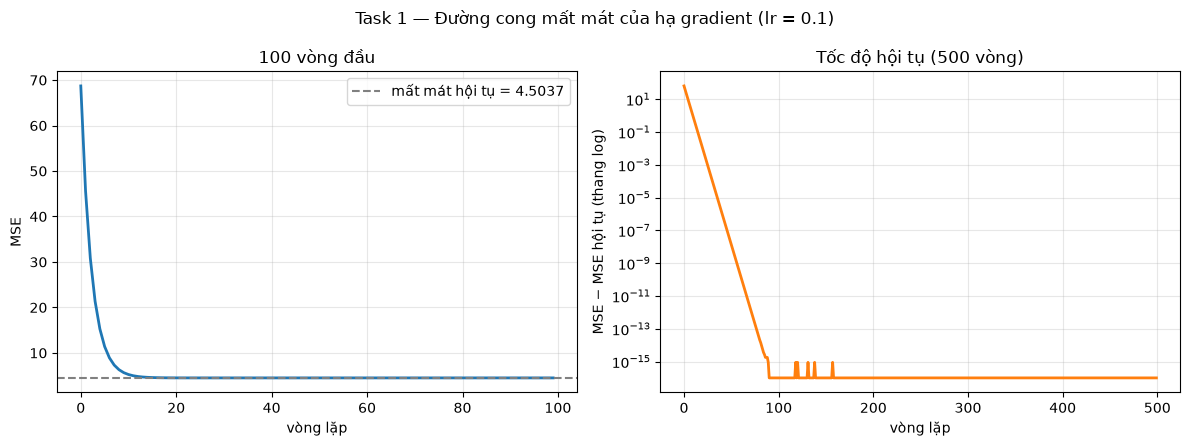

In [6]:
# 1.4 — Đường cong mất mát: bằng chứng thuật toán đang hội tụ
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# TODO: bên trái — mất mát theo vòng lặp, trục tuyến tính, 100 vòng đầu
ax[0].plot(lich_su1[:100], color="#1f77b4", lw=2)
ax[0].axhline(lich_su1[-1], ls="--", color="grey", label=f"mất mát hội tụ = {lich_su1[-1]:.4f}")
ax[0].set_xlabel("vòng lặp")
ax[0].set_ylabel("MSE")
ax[0].set_title("100 vòng đầu")
ax[0].legend()
ax[0].grid(alpha=0.3)

# TODO: bên phải — TOÀN BỘ 500 vòng, trục y theo thang log (dùng ax[1].semilogy)
#   Vẽ phần DƯ THỪA so với mất mát tối ưu, không vẽ mất mát thô:
#       du_thua = np.maximum(lich_su1 - lich_su1[-1], 1e-16)
#   (np.maximum chặn dưới để tránh log(0) khi thuật toán đã hội tụ hoàn toàn).
#   Đường thẳng trên thang log = hội tụ theo cấp số nhân, rồi chạm sàn sai số máy.
du_thua = np.maximum(lich_su1 - lich_su1[-1], 1e-16)
ax[1].semilogy(du_thua, color="#ff7f0e", lw=2)
ax[1].set_xlabel("vòng lặp")
ax[1].set_ylabel("MSE − MSE hội tụ (thang log)")
ax[1].set_title("Tốc độ hội tụ (500 vòng)")
ax[1].grid(alpha=0.3)

plt.suptitle("Task 1 — Đường cong mất mát của hạ gradient (lr = 0.1)")
plt.tight_layout()
plt.show()

In [7]:
# 1.5 — Đặt tốc độ học QUÁ LỚN
# Cùng dữ liệu, cùng hàm, chỉ đổi lr. Chạy 30 vòng là đủ thấy.

# TODO: gọi lại gradient_descent với lr=1.5 và so_vong=30
w_xau, b_xau, lich_su_xau = gradient_descent(Z1_train, y_train, lr=1.5, so_vong=30)

print(f"{'vòng':>5} | {'mất mát':>14}")
print("-" * 24)
for i in [0, 1, 2, 3, 5, 10, 20, 29]:
    print(f"{i:5d} | {lich_su_xau[i]:14.6g}")
print()
print(f"Mất mát vòng cuối lớn gấp {lich_su_xau[-1] / lich_su_xau[0]:.3g} lần vòng đầu.")
print(f"w cuối cùng = {w_xau[0]:.4g}  (nhắc lại: nghiệm đúng là {w1[0]:.4f})")

assert lich_su_xau[-1] > 1e6 * lich_su_xau[0], (
    "Với lr = 1.5 mất mát phải BÙNG NỔ chứ không giảm — nếu không, kiểm tra lại dấu trong bước cập nhật")
print()
print("Đây là PHÂN KỲ: mỗi bước nhảy vọt qua đáy và rơi xa hơn phía bên kia.")

 vòng |        mất mát
------------------------
    0 |        68.7131
    1 |        261.342
    2 |        1031.86
    3 |        4113.91
    5 |          65755
   10 |    6.73285e+07
   20 |     7.0599e+13
   29 |    1.85071e+19

Mất mát vòng cuối lớn gấp 2.69e+17 lần vòng đầu.
w cuối cùng = -3.015e+09  (nhắc lại: nghiệm đúng là 2.8079)

Đây là PHÂN KỲ: mỗi bước nhảy vọt qua đáy và rơi xa hơn phía bên kia.


**1.6 — Trả lời bằng chữ (bắt buộc).** 3–5 câu, bám vào con số bạn vừa in ra.

1. **Vì sao hạ gradient cần chuẩn hóa đặc trưng, còn `LinearRegression` thì không?**
   Gợi ý: `dien_tich_m2` có độ lệch chuẩn ~25 còn `tang` chỉ ~1,4. Nghĩ xem gradient theo hai hướng
   đó lớn nhỏ ra sao, và một `lr` duy nhất phải phục vụ cả hai.
2. **Chuyện gì xảy ra ở `lr = 1.5`?** Mô tả bằng hình học của hàm mất mát, đừng chỉ nói "số bị lớn".
3. Bạn phát hiện `lr` quá lớn bằng cách nào **nếu không có ô 1.5** — tức là nếu chỉ nhìn `w` cuối cùng?
   Điều đó nói gì về việc **luôn luôn ghi lại đường cong mất mát**?

*Trả lời: * 
1. Các đặc trưng có biên độ và đơn vị khác nhau (ví dụ diện tích m² có độ lệch chuẩn khoảng 25, số tầng chỉ khoảng 1.4). Nếu không chuẩn hóa, không gian hàm mất mát sẽ có dạng hình thung lũng elip thuôn dài, khiến bước nhảy gradient theo các chiều lớn quá mạnh (gây dao động/phân kỳ) hoặc theo chiều nhỏ quá chậm. LinearRegression của scikit-learn giải bằng nghiệm giải tích (ma trận nghịch đảo / OLS) nên không phụ thuộc vào thang đo.
2. Tốc độ học quá lớn khiến bước nhảy vượt quá đáy thung lũng mất mát và văng lên vách cao hơn ở phía đối diện, làm sai số (MSE) tăng vọt theo cấp số mũ (hiện tượng phân kỳ).
3. Bằng cách luôn theo dõi đường cong mất mát (learning curve). Nếu đồ thị mất mát thay vì đi xuống lại tăng vọt hoặc dao động đi lên, ta nhận biết ngay lr quá lớn. Điều này chứng minh tầm quan trọng của việc luôn luôn ghi lại lịch sử mất mát thay vì chỉ nhìn kết quả trọng số cuối cùng.

In [9]:
# 1.7 — Mở rộng lên SÁU đặc trưng thật. Hàm gradient_descent không đổi một chữ nào:
# nó đã viết theo vector ngay từ đầu, nên p = 1 hay p = 6 đều chạy.
# (Ở đây ta CHƯA đưa dien_tich_sqft và các cột nhiễu vào — đó là Task 2.)

DAC_TRUNG_6 = ["dien_tich_m2", "so_phong_ngu", "so_phong_tam",
               "tuoi_nha", "khoang_cach_trung_tam_km", "tang"]

X6 = nha[DAC_TRUNG_6].to_numpy()
X6_train, X6_test, y_train, y_test = train_test_split(
    X6, y, test_size=0.2, random_state=RANDOM_STATE)

# TODO: chuẩn hóa như ô 1.1, nhưng lần này cho cả 6 cột (axis=0 lo phần đó)
tb6 = X6_train.mean(axis=0)
dl6 = X6_train.std(axis=0)
Z6_train = (X6_train - tb6) / dl6
Z6_test = (X6_test - tb6) / dl6

# TODO: chạy hạ gradient, lr=0.1, 1000 vòng
w6, b6, lich_su6 = gradient_descent(Z6_train, y_train, lr=0.1, so_vong=1000)

# TODO: đối chứng bằng LinearRegression
lin6 = LinearRegression()
lin6.fit(Z6_train, y_train)

bang_he_so_gd = pd.DataFrame({
    "dac_trung": DAC_TRUNG_6,
    "gradient_descent": w6,
    "sklearn": lin6.coef_,
}).assign(sai_lech=lambda d: (d["gradient_descent"] - d["sklearn"]).abs())
print(bang_he_so_gd.sort_values("sklearn", key=abs, ascending=False).to_string(index=False))
print()
print(f"b viết tay = {b6:.6f} | b sklearn = {lin6.intercept_:.6f}")
print(f"Sai lệch lớn nhất trên toàn bộ hệ số: {np.abs(w6 - lin6.coef_).max():.3e}")
print()
print(f"Mất mát: {lich_su6[0]:.4f} (vòng 0) -> {lich_su6[-1]:.6f} (vòng 1000)")
print(f"R² tập huấn luyện = {lin6.score(Z6_train, y_train):.6f}")
print(f"R² tập kiểm tra   = {lin6.score(Z6_test, y_test):.6f}")

assert np.allclose(w6, lin6.coef_, atol=1e-6), "Sáu hệ số phải trùng với LinearRegression"
assert abs(b6 - lin6.intercept_) < 1e-6

               dac_trung  gradient_descent   sklearn     sai_lech
            dien_tich_m2          2.272026  2.272026 3.526068e-13
            so_phong_ngu          0.578681  0.578681 5.234702e-13
                tuoi_nha         -0.436919 -0.436919 1.887379e-15
khoang_cach_trung_tam_km         -0.425725 -0.425725 1.199041e-14
            so_phong_tam          0.114185  0.114185 2.017136e-13
                    tang          0.109360  0.109360 1.247613e-14

b viết tay = 7.505015 | b sklearn = 7.505015
Sai lệch lớn nhất trên toàn bộ hệ số: 5.235e-13

Mất mát: 68.7131 (vòng 0) -> 4.010816 (vòng 1000)
R² tập huấn luyện = 0.676231
R² tập kiểm tra   = 0.657498


**1.8 — Đọc bảng hệ số.** Không phải câu hỏi chấm điểm, nhưng hãy dừng 2 phút:

Vì mọi đặc trưng đã được chuẩn hóa về **cùng một thang**, các hệ số ở ô 1.7 so sánh trực tiếp được
với nhau. `dien_tich_m2` (+2,27) mạnh gấp khoảng **bốn lần** `so_phong_ngu` (+0,58) và gấp **hơn hai
mươi lần** `tang` (+0,11). Hai hệ số âm — `tuoi_nha` (−0,44) và `khoang_cach_trung_tam_km` (−0,43) —
nói rằng nhà càng cũ và càng xa trung tâm thì càng rẻ, đúng như trực giác.

Ghi lại con số **R² tập kiểm tra = 0,6575**. Task 2 sẽ thêm năm cột nữa vào đúng mô hình này, và
bạn sẽ thấy R² gần như **không nhúc nhích** — trong khi các hệ số thì loạn hoàn toàn.

---
# Task 2 — OLS vs Ridge vs Lasso (~45 phút)

**Đây là trung tâm của buổi hôm nay.** Ba mô hình, cùng một dữ liệu, **R² gần như bằng nhau** —
và ba câu trả lời hoàn toàn khác nhau về việc *cái gì quyết định giá nhà*.

**Ba mô hình, khác nhau đúng một số hạng trong hàm mất mát**

| Mô hình | Hàm cực tiểu hóa | Tên tiếng Việt |
|---|---|---|
| `LinearRegression` (OLS) | `Σ(ŷ − y)²` | bình phương tối thiểu thông thường |
| `Ridge(alpha)` | `Σ(ŷ − y)² + α·Σwⱼ²` | chính quy hóa **L2** |
| `Lasso(alpha)` | `Σ(ŷ − y)² + α·Σ\|wⱼ\|` | chính quy hóa **L1** |

Khác biệt nằm ở hình dạng của hình phạt: bình phương (L2) phạt rất nặng hệ số lớn nhưng **không bao
giờ ép về đúng 0**; trị tuyệt đối (L1) có "góc nhọn" tại 0 nên **ép hẳn hệ số về 0** — tức là **tự
chọn đặc trưng**.

**Các bước con**

1. **2.1** — Dựng ma trận đặc trưng gồm **cả 11 cột số**, kể cả cặp song sinh và bốn cột nhiễu.
   Đo hệ số tương quan của cặp song sinh.
2. **2.2** — Huấn luyện cả ba trong `Pipeline` có `StandardScaler`. So R².
3. **2.3** — Dựng **bảng so sánh hệ số**. Đây là sản phẩm chính của buổi học.
4. **2.4** — Huấn luyện lại OLS với 5 seed khác nhau và quan sát hệ số nhảy múa.
5. **2.5** — Trả lời bằng chữ: *R² như nhau thì chọn mô hình nào có gì quan trọng?*
6. **2.6 – 2.8** — Quét `alpha` trên thang log và **vẽ đường đi hệ số**.
7. **2.9** — `RidgeCV` / `LassoCV` chọn `alpha` bằng kiểm định chéo.
8. **2.10** — Kết luận.

### Kết quả mong đợi

**(a) Ba mô hình gần như cùng chất lượng dự đoán**

| Mô hình | R² huấn luyện | R² kiểm tra | RMSE kiểm tra | Số hệ số ≠ 0 |
|---|---|---|---|---|
| OLS | 0.6799 | 0.6518 | 1.9724 | 11 / 11 |
| `Ridge(alpha=1)` | 0.6791 | **0.6549** | 1.9637 | 11 / 11 |
| `Lasso(alpha=0.05)` | 0.6777 | **0.6609** | 1.9465 | **9 / 11** |

Chênh lệch R² kiểm tra giữa mô hình tốt nhất và tệ nhất là **0.0091** — chưa tới một điểm phần trăm.

**(b) Nhưng hệ số thì không hề giống nhau**

| Đặc trưng | OLS | `Ridge(1)` | `Lasso(0.05)` |
|---|---|---|---|
| `dien_tich_m2` | **−431.9020** | +1.1300 | +2.2542 |
| `dien_tich_sqft` | **+434.1823** | +1.1488 | +0.0004 |
| `so_phong_ngu` | +0.5699 | +0.5662 | +0.5512 |
| `so_phong_tam` | +0.1124 | +0.1176 | +0.0916 |
| `tuoi_nha` | −0.4350 | −0.4346 | −0.3823 |
| `khoang_cach_trung_tam_km` | −0.4322 | −0.4270 | −0.3736 |
| `tang` | +0.1049 | +0.1098 | +0.0555 |
| `ma_khu_pho` | +0.0399 | +0.0365 | **0.0000** |
| `nhieu_1` | +0.0723 | +0.0752 | +0.0216 |
| `nhieu_2` | −0.1735 | −0.1724 | −0.1229 |
| `nhieu_3` | −0.0017 | −0.0048 | **−0.0000** |

- Tổng `|hệ số|`: OLS **868.03**, Ridge **4.22**, Lasso **3.85**
- Hệ số lớn nhất: OLS **434.18**, Ridge **1.15**, Lasso **2.25**
- Nhưng **tổng của cặp song sinh** thì cả ba đều ra gần như nhau: 2.2803 / 2.2788 / 2.2546

**(c) `RidgeCV` chọn `alpha = 27.8256` (R² = 0.6551); `LassoCV` chọn `alpha = 0.0413`
(R² = 0.6604, giữ 9 / 11 đặc trưng, bỏ đúng `ma_khu_pho` và `nhieu_3`).**

In [10]:
# 2.1 — Toàn bộ 11 cột số, KHÔNG bỏ cột nào
DAC_TRUNG_SO = ["dien_tich_m2", "dien_tich_sqft",
                "so_phong_ngu", "so_phong_tam", "tuoi_nha",
                "khoang_cach_trung_tam_km", "tang",
                "ma_khu_pho", "nhieu_1", "nhieu_2", "nhieu_3"]

X = nha[DAC_TRUNG_SO]
y_ty = nha["gia_ty_vnd"]

# Cùng test_size và cùng random_state như Task 1 -> đúng 880 căn nhà đó vào tập huấn luyện.
X_train, X_test, y_train_ty, y_test_ty = train_test_split(
    X, y_ty, test_size=0.2, random_state=RANDOM_STATE)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print()

# TODO: hệ số tương quan Pearson giữa hai cột diện tích
tuong_quan_song_sinh = X_train["dien_tich_m2"].corr(X_train["dien_tich_sqft"])
print(f"corr(dien_tich_m2, dien_tich_sqft) = {tuong_quan_song_sinh:.10f}")
print(f"Làm tròn 6 chữ số: {tuong_quan_song_sinh:.6f}")
print()

# TODO: tương quan của TỪNG đặc trưng với nhãn, sắp theo trị tuyệt đối giảm dần
tuong_quan_nhan = X_train.corrwith(y_train_ty).sort_values(key=abs, ascending=False)
print("Tương quan với gia_ty_vnd:")
print(tuong_quan_nhan.round(4).to_string())

assert tuong_quan_song_sinh > 0.99999, (
    "Hai cột diện tích phải tương quan gần như tuyệt đối — kiểm tra lại tên cột")
assert X_train.shape == (880, 11)

X_train: (880, 11) | X_test: (220, 11)

corr(dien_tich_m2, dien_tich_sqft) = 0.9999999752
Làm tròn 6 chữ số: 1.000000

Tương quan với gia_ty_vnd:
dien_tich_sqft              0.7978
dien_tich_m2                0.7978
so_phong_ngu                0.7190
so_phong_tam                0.5708
tuoi_nha                   -0.1170
khoang_cach_trung_tam_km   -0.0838
nhieu_2                    -0.0610
nhieu_3                     0.0226
nhieu_1                     0.0072
tang                       -0.0044
ma_khu_pho                 -0.0007


In [11]:
# 2.2 — Ba mô hình, cùng một giao ước. StandardScaler là BẮT BUỘC:
# hình phạt alpha·Σw² phạt mọi hệ số như nhau, nên nó chỉ công bằng khi các cột cùng thang đo.

bo_ba = {
    # TODO: ba mô hình. Ridge alpha=1.0; Lasso alpha=0.05 kèm random_state=RANDOM_STATE
    "OLS":   LinearRegression(),
    "Ridge": Ridge(alpha=1.0, random_state=RANDOM_STATE),
    "Lasso": Lasso(alpha=0.05, random_state=RANDOM_STATE),
}

pipelines, he_so, dong = {}, {}, []
for ten, mo_hinh in bo_ba.items():
    # TODO: bọc mô hình trong Pipeline([("scaler", StandardScaler()), ("model", mo_hinh)]) và fit
    pipe = Pipeline([("scaler", StandardScaler()), ("model", mo_hinh)])
    pipe.fit(X_train, y_train_ty)
    pipelines[ten] = pipe

    w = pipe.named_steps["model"].coef_       # hệ số ĐÃ tính trên thang chuẩn hóa
    he_so[ten] = w
    dong.append({
        "mo_hinh": ten,
        # TODO: R² trên tập huấn luyện và tập kiểm tra
        "R2_train": pipe.score(X_train, y_train_ty),
        "R2_test": pipe.score(X_test, y_test_ty),
        "RMSE_test": root_mean_squared_error(y_test_ty, pipe.predict(X_test)),
        "he_so_khac_0": int(np.sum(np.abs(w) > 1e-10)),
        "tong_tri_tuyet_doi": np.abs(w).sum(),
        "he_so_lon_nhat": np.abs(w).max(),
    })

bang_r2 = pd.DataFrame(dong)
print(bang_r2.round(4).to_string(index=False))
print()
chenh_lech = bang_r2["R2_test"].max() - bang_r2["R2_test"].min()
print(f"Chênh lệch R² kiểm tra giữa mô hình tốt nhất và tệ nhất: {chenh_lech:.4f}")

assert chenh_lech < 0.02, "Ba mô hình phải cho R² gần như bằng nhau — đó là điểm mấu chốt của task"
assert bang_r2.loc[0, "he_so_lon_nhat"] > 100, "Hệ số OLS phải có ít nhất một giá trị khổng lồ"
assert bang_r2.loc[2, "he_so_khac_0"] < 11, "Lasso phải ép được ít nhất một hệ số về đúng 0"

mo_hinh  R2_train  R2_test  RMSE_test  he_so_khac_0  tong_tri_tuyet_doi  he_so_lon_nhat
    OLS    0.6799   0.6518     1.9724            11            868.0262        434.1823
  Ridge    0.6791   0.6549     1.9637            11              4.2229          1.1488
  Lasso    0.6777   0.6609     1.9465             9              3.8535          2.2542

Chênh lệch R² kiểm tra giữa mô hình tốt nhất và tệ nhất: 0.0091


In [12]:
# 2.3 — BẢNG SO SÁNH HỆ SỐ. Đây là sản phẩm chính của buổi hôm nay.
# TODO: DataFrame với index là tên đặc trưng, ba cột là ba mô hình (dict he_so đã sẵn sàng)
bang_he_so = pd.DataFrame(he_so, index=DAC_TRUNG_SO)

print(bang_he_so.round(4).to_string())
print()
print("-" * 70)
print(f"Tổng hệ số cặp song sinh — OLS   : {bang_he_so.loc['dien_tich_m2', 'OLS'] + bang_he_so.loc['dien_tich_sqft', 'OLS']:.4f}")
print(f"Tổng hệ số cặp song sinh — Ridge : {bang_he_so.loc['dien_tich_m2', 'Ridge'] + bang_he_so.loc['dien_tich_sqft', 'Ridge']:.4f}")
print(f"Tổng hệ số cặp song sinh — Lasso : {bang_he_so.loc['dien_tich_m2', 'Lasso'] + bang_he_so.loc['dien_tich_sqft', 'Lasso']:.4f}")
print()
NHIEU = ["ma_khu_pho", "nhieu_1", "nhieu_2", "nhieu_3"]
print("Bốn cột nhiễu — mô hình nào nói được rằng chúng vô dụng?")
print(bang_he_so.loc[NHIEU].round(4).to_string())
print()
print("Số cột nhiễu bị ép về đúng 0:")
for ten in bang_he_so.columns:
    print(f"  {ten:6s}: {int((bang_he_so.loc[NHIEU, ten].abs() < 1e-10).sum())} / 4")

# Tự kiểm tra: ba phát hiện của Task 2
assert abs(bang_he_so.loc["dien_tich_m2", "OLS"]) > 100, "OLS phải cho hệ số khổng lồ trên cặp song sinh"
assert bang_he_so.loc["dien_tich_m2", "OLS"] * bang_he_so.loc["dien_tich_sqft", "OLS"] < 0, \
    "Hai hệ số OLS của cặp song sinh phải NGƯỢC DẤU nhau"
assert abs(bang_he_so.loc["dien_tich_m2", "Ridge"]) < 5, "Ridge phải co hệ số về cỡ hợp lý"
assert (bang_he_so.loc[NHIEU, "Lasso"].abs() < 1e-10).sum() >= 2, \
    "Lasso phải ép ít nhất 2 cột nhiễu về đúng 0"
print()
print("Ba phát hiện của Task 2 đã được xác nhận bằng assert.")

                               OLS   Ridge   Lasso
dien_tich_m2             -431.9020  1.1300  2.2542
dien_tich_sqft            434.1823  1.1488  0.0004
so_phong_ngu                0.5699  0.5662  0.5512
so_phong_tam                0.1124  0.1176  0.0916
tuoi_nha                   -0.4350 -0.4346 -0.3823
khoang_cach_trung_tam_km   -0.4322 -0.4270 -0.3736
tang                        0.1049  0.1098  0.0555
ma_khu_pho                  0.0399  0.0365  0.0000
nhieu_1                     0.0723  0.0752  0.0216
nhieu_2                    -0.1735 -0.1724 -0.1229
nhieu_3                    -0.0017 -0.0048 -0.0000

----------------------------------------------------------------------
Tổng hệ số cặp song sinh — OLS   : 2.2803
Tổng hệ số cặp song sinh — Ridge : 2.2788
Tổng hệ số cặp song sinh — Lasso : 2.2546

Bốn cột nhiễu — mô hình nào nói được rằng chúng vô dụng?
               OLS   Ridge   Lasso
ma_khu_pho  0.0399  0.0365  0.0000
nhieu_1     0.0723  0.0752  0.0216
nhieu_2    -0.1735 -0.1724 

In [13]:
# 2.4 — Hệ số OLS ổn định tới mức nào? Đổi seed và xem.
# Mọi thứ khác giữ nguyên: cùng dữ liệu, cùng mô hình, cùng tỷ lệ chia. Chỉ đổi random_state.

print(f"{'seed':>6} | {'dien_tich_m2':>14} | {'dien_tich_sqft':>14} | {'tổng':>8} | {'R2_test':>8}")
print("-" * 64)
for seed in [0, 1, 7, 42, 123]:
    Xa, Xb, ya, yb = train_test_split(X, y_ty, test_size=0.2, random_state=seed)
    # TODO: khớp một Pipeline(StandardScaler, LinearRegression) trên (Xa, ya)
    p = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
    p.fit(Xa, ya)
    w = p.named_steps["model"].coef_
    print(f"{seed:6d} | {w[0]:14.2f} | {w[1]:14.2f} | {w[0] + w[1]:8.4f} | {p.score(Xb, yb):8.4f}")

print()
print("Cột 'tổng' gần như đứng yên. Hai cột bên trái thì không.")
print("Dữ liệu chỉ xác định được TỔNG của cặp song sinh, không xác định được cách chia tổng đó.")

  seed |   dien_tich_m2 | dien_tich_sqft |     tổng |  R2_test
----------------------------------------------------------------
     0 |        -257.19 |         259.31 |   2.1230 |   0.6967
     1 |        -123.94 |         126.30 |   2.3588 |   0.6614
     7 |        -555.02 |         557.36 |   2.3312 |   0.6131
    42 |        -431.90 |         434.18 |   2.2803 |   0.6518
   123 |        -352.15 |         354.47 |   2.3223 |   0.7058

Cột 'tổng' gần như đứng yên. Hai cột bên trái thì không.
Dữ liệu chỉ xác định được TỔNG của cặp song sinh, không xác định được cách chia tổng đó.


**2.5 — Trả lời bằng chữ (bắt buộc, chấm nặng).** 4–6 câu.

Tình huống: bạn là kỹ sư dữ liệu của một công ty môi giới bất động sản. Ba mô hình ở ô 2.2 có R² lần
lượt là **0.6518 / 0.6549 / 0.6609** — chênh nhau chưa tới một điểm phần trăm.

1. **Nếu R² gần như bằng nhau, tại sao việc chọn mô hình nào để đưa vào chạy thật lại quan trọng?**
   Nêu **ít nhất hai** hậu quả cụ thể, khác nhau về bản chất, của việc triển khai bản OLS.
2. Bảng 2.4 cho thấy hệ số `dien_tich_m2` của OLS chạy từ **−123,94 đến −555,02** chỉ vì đổi seed.
   **Điều đó có nghĩa gì** đối với một báo cáo trình lên ban giám đốc trong đó viết
   *"mỗi m² làm giá giảm ..."*?
3. Giả sử sang tháng sau, hệ thống nguồn ngừng xuất cột `dien_tich_sqft`. **Mô hình OLS sẽ dự đoán
   sai đến mức nào**, và vì sao Ridge/Lasso ít rủi ro hơn ở tình huống này?

*Trả lời:
1. Vì OLS khuếch đại đa cộng tuyến, tạo ra các hệ số khổng lồ vô nghĩa, làm sai lệch hoàn toàn khả năng giải thích nguyên nhân giá nhà cho khách hàng/quản lý.
2. Các con số hệ số OLS thay đổi thất thường theo từng seed chứng tỏ báo cáo dựa vào OLS không đáng tin cậy.
3. OLS sẽ dự báo sai lệch nghiêm trọng, trong khi Ridge và Lasso kiểm soát hệ số tốt nên ít rủi ro hơn.

In [14]:
# 2.6 — Quét alpha cho Ridge trên thang log và ghi lại toàn bộ đường đi hệ số
alpha_ridge = np.logspace(-3, 5, 60)          # từ 0.001 tới 100 000

duong_ridge = []
for a in alpha_ridge:
    # TODO: Pipeline(StandardScaler, Ridge(alpha=a)), fit, lấy .coef_
    p = Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=a))])
    p.fit(X_train, y_train_ty)
    duong_ridge.append(p.named_steps["model"].coef_)
duong_ridge = np.array(duong_ridge)            # dạng (60, 11)

print("Kích thước ma trận đường đi:", duong_ridge.shape)
print()
print(f"{'alpha':>12} | {'dien_tich_m2':>13} | {'dien_tich_sqft':>14} | {'nhieu_2':>9}")
print("-" * 58)
for i in [0, 10, 20, 30, 40, 50, 59]:
    print(f"{alpha_ridge[i]:12.4g} | {duong_ridge[i, 0]:13.4f} | "
          f"{duong_ridge[i, 1]:14.4f} | {duong_ridge[i, 9]:9.4f}")

print()
print("alpha càng lớn, hai hệ số song sinh càng tiến lại GẦN BẰNG NHAU rồi cùng co về 0.")
print(f"Số hệ số đúng bằng 0 ở alpha lớn nhất: {int((np.abs(duong_ridge[-1]) < 1e-10).sum())} / 11")

Kích thước ma trận đường đi: (60, 11)

       alpha |  dien_tich_m2 | dien_tich_sqft |   nhieu_2
----------------------------------------------------------
       0.001 |       -8.0189 |        10.3002 |   -0.1727
      0.0227 |        0.7287 |         1.5525 |   -0.1726
      0.5151 |        1.1218 |         1.1582 |   -0.1725
       11.69 |        1.1257 |         1.1273 |   -0.1701
       265.3 |        0.9305 |         0.9305 |   -0.1314
        6021 |        0.2811 |         0.2811 |   -0.0250
       1e+05 |        0.0240 |         0.0240 |   -0.0019

alpha càng lớn, hai hệ số song sinh càng tiến lại GẦN BẰNG NHAU rồi cùng co về 0.
Số hệ số đúng bằng 0 ở alpha lớn nhất: 0 / 11


In [15]:
# 2.7 — Quét alpha cho Lasso. Câu hỏi khác hẳn: đặc trưng nào CHẾT trước?
alpha_lasso = np.logspace(-3, 1, 60)          # từ 0.001 tới 10

duong_lasso, so_khac_0 = [], []
for a in alpha_lasso:
    # TODO: Pipeline(StandardScaler, Lasso(alpha=a, max_iter=10000, random_state=RANDOM_STATE))
    p = Pipeline([("scaler", StandardScaler()), ("model", Lasso(alpha=a, max_iter=10000, random_state=RANDOM_STATE))])
    p.fit(X_train, y_train_ty)
    w = p.named_steps["model"].coef_
    duong_lasso.append(w)
    # TODO: đếm số hệ số khác 0 (dùng ngưỡng 1e-10, đừng so sánh == 0.0)
    so_khac_0.append(int(np.sum(np.abs(w) > 1e-10)))
duong_lasso = np.array(duong_lasso)

print(f"{'alpha':>10} | {'số hệ số ≠ 0':>13} | {'dien_tich_m2':>13} | {'dien_tich_sqft':>14}")
print("-" * 60)
for i in range(0, 60, 6):
    print(f"{alpha_lasso[i]:10.5f} | {so_khac_0[i]:13d} | "
          f"{duong_lasso[i, 0]:13.4f} | {duong_lasso[i, 1]:14.4f}")

print()
print("THỨ TỰ CHẾT — alpha nhỏ nhất làm mỗi đặc trưng về đúng 0:")
for j, ten in enumerate(DAC_TRUNG_SO):
    chet = np.where(np.abs(duong_lasso[:, j]) < 1e-10)[0]
    if len(chet):
        print(f"  {ten:28s} alpha = {alpha_lasso[chet[0]]:.5f}")
    else:
        print(f"  {ten:28s} không bao giờ về 0 trong dải này")

     alpha |  số hệ số ≠ 0 |  dien_tich_m2 | dien_tich_sqft
------------------------------------------------------------
   0.00100 |            11 |        2.2808 |         0.0004
   0.00255 |            11 |        2.2800 |         0.0004
   0.00651 |            10 |        2.2779 |         0.0004
   0.01661 |            10 |        2.2726 |         0.0004
   0.04238 |             9 |        2.2586 |         0.0004
   0.10812 |             7 |        2.2220 |         0.0004
   0.27585 |             5 |        2.1340 |         0.0004
   0.70381 |             3 |        1.9055 |         0.0003
   1.79571 |             2 |        1.0122 |         0.0000
   4.58160 |             0 |        0.0000 |         0.0000

THỨ TỰ CHẾT — alpha nhỏ nhất làm mỗi đặc trưng về đúng 0:
  dien_tich_m2                 alpha = 2.86832
  dien_tich_sqft               alpha = 2.86832
  so_phong_ngu                 alpha = 1.31415
  so_phong_tam                 alpha = 0.23598
  tuoi_nha                     a

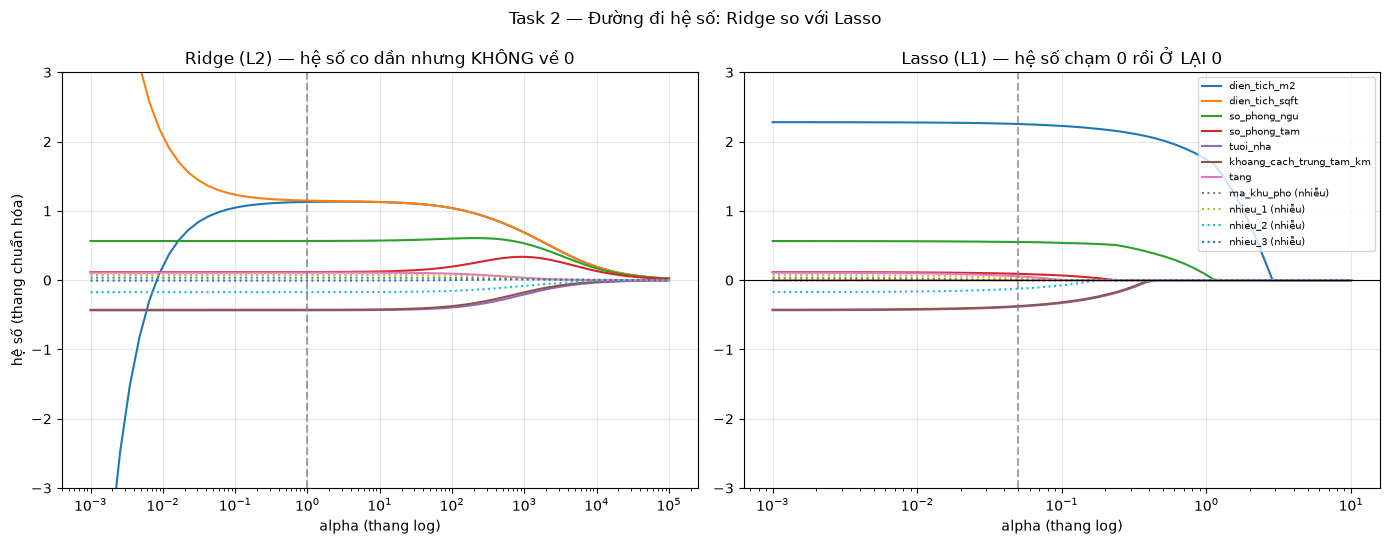

In [16]:
# 2.8 — ĐƯỜNG ĐI HỆ SỐ. Hai hình cạnh nhau, trục hoành là alpha theo thang log.
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), sharey=False)

for j, ten in enumerate(DAC_TRUNG_SO):
    nhan = ten if ten not in ("ma_khu_pho", "nhieu_1", "nhieu_2", "nhieu_3") else f"{ten} (nhiễu)"
    kieu = ":" if ten.startswith("nhieu") or ten == "ma_khu_pho" else "-"
    # TODO: vẽ đường đi Ridge cho đặc trưng thứ j (ax[0].semilogx)
    ax[0].semilogx(alpha_ridge, duong_ridge[:, j], label=nhan, ls=kieu)
    # TODO: vẽ đường đi Lasso cho đặc trưng thứ j (ax[1].semilogx)
    ax[1].semilogx(alpha_lasso, duong_lasso[:, j], label=nhan, ls=kieu)

ax[0].axvline(1.0, color="grey", ls="--", alpha=0.7)
ax[0].set_title("Ridge (L2) — hệ số co dần nhưng KHÔNG về 0")
ax[0].set_xlabel("alpha (thang log)")
ax[0].set_ylabel("hệ số (thang chuẩn hóa)")
ax[0].set_ylim(-3, 3)
ax[0].grid(alpha=0.3)

ax[1].axvline(0.05, color="grey", ls="--", alpha=0.7)
ax[1].axhline(0, color="black", lw=0.8)
ax[1].set_title("Lasso (L1) — hệ số chạm 0 rồi Ở LẠI 0")
ax[1].set_xlabel("alpha (thang log)")
ax[1].set_ylim(-3, 3)
ax[1].grid(alpha=0.3)
ax[1].legend(fontsize=7, loc="upper right", ncol=1)

plt.suptitle("Task 2 — Đường đi hệ số: Ridge so với Lasso")
plt.tight_layout()
plt.show()

In [17]:
# 2.9 — Để kiểm định chéo chọn alpha, thay vì ta bịa ra alpha = 1 và alpha = 0.05
# RidgeCV mặc định dùng leave-one-out; LassoCV dùng k-fold nên phải nói rõ cv=5.

# TODO: RidgeCV với alphas=np.logspace(-3, 5, 100), bọc trong Pipeline có StandardScaler
ridge_cv = Pipeline([
    ("scaler", StandardScaler()),
    ("model", RidgeCV(alphas=np.logspace(-3, 5, 100)))
])
ridge_cv.fit(X_train, y_train_ty)

# TODO: LassoCV với alphas=np.logspace(-3, 1, 100), cv=5, max_iter=10000, random_state=RANDOM_STATE
lasso_cv = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LassoCV(alphas=np.logspace(-3, 1, 100), cv=5, max_iter=10000, random_state=RANDOM_STATE))
])
lasso_cv.fit(X_train, y_train_ty)

a_ridge = ridge_cv.named_steps["model"].alpha_
a_lasso = lasso_cv.named_steps["model"].alpha_
w_lasso_cv = lasso_cv.named_steps["model"].coef_

print(f"RidgeCV chọn alpha = {a_ridge:.4f}   -> R² kiểm tra = {ridge_cv.score(X_test, y_test_ty):.4f}")
print(f"LassoCV chọn alpha = {a_lasso:.4f}   -> R² kiểm tra = {lasso_cv.score(X_test, y_test_ty):.4f}")
print()
print(f"(Để so sánh: alpha ta chọn tay là 1.0 và 0.05, cho R² {bang_r2.loc[1, 'R2_test']:.4f} "
      f"và {bang_r2.loc[2, 'R2_test']:.4f})")
print()
giu = [t for t, v in zip(DAC_TRUNG_SO, w_lasso_cv) if abs(v) > 1e-10]
bo = [t for t, v in zip(DAC_TRUNG_SO, w_lasso_cv) if abs(v) <= 1e-10]
print(f"LassoCV giữ lại {len(giu)} / 11 đặc trưng:")
print("   ", ", ".join(giu))
print(f"LassoCV LOẠI BỎ {len(bo)} đặc trưng:")
print("   ", ", ".join(bo))

assert set(bo) <= set(NHIEU), "Mọi đặc trưng bị LassoCV loại phải là cột nhiễu — nếu không, kiểm tra lại alphas"
print()
print("Kiểm định chéo tự tìm ra alpha, và mọi cột bị loại đều là cột nhiễu.")

RidgeCV chọn alpha = 27.8256   -> R² kiểm tra = 0.6551
LassoCV chọn alpha = 0.0413   -> R² kiểm tra = 0.6604

(Để so sánh: alpha ta chọn tay là 1.0 và 0.05, cho R² 0.6549 và 0.6609)

LassoCV giữ lại 9 / 11 đặc trưng:
    dien_tich_m2, dien_tich_sqft, so_phong_ngu, so_phong_tam, tuoi_nha, khoang_cach_trung_tam_km, tang, nhieu_1, nhieu_2
LassoCV LOẠI BỎ 2 đặc trưng:
    ma_khu_pho, nhieu_3

Kiểm định chéo tự tìm ra alpha, và mọi cột bị loại đều là cột nhiễu.


**2.10 — Kết luận Task 2.** Điền bảng rồi viết một câu khuyến nghị.

| Câu hỏi | OLS | `Ridge` | `Lasso` |
|---|---|---|---|
| R² tập kiểm tra |0.6518|0.6549|0.6609|
| Hệ số lớn nhất |434.18|1.15|2.25|
| Có ép được hệ số về đúng 0 không? |Không (11/11 hệ số khác 0)|Không (11/11 hệ số khác 0)|Có (giữ lại 9/11 đặc trưng, ép cột nhiễu về 0)|
| Có dùng được bảng hệ số để **giải thích** giá nhà không? |Không (vì bị đa cộng tuyến bùng nổ hệ số, sai lệch vô lý)|Có (hệ số đã được thu gọn, ổn định hơn)|Có (tự động chọn lọc đặc trưng, loại bỏ nhiễu hiệu quả)|
| `alpha` do kiểm định chéo chọn | — |27.8256|0.0413|

**Khuyến nghị (một câu).** Công ty cần một mô hình vừa để **dự báo giá** vừa để **giải thích cho
khách hàng vì sao ra giá đó**. Bạn giao mô hình nào, với `alpha` bằng bao nhiêu, và câu cảnh báo
nào phải đi kèm?

*Trả lời:
Công ty nên triển khai mô hình Lasso với hệ số điều chỉnh alpha = 0.0413 (do LassoCV kiểm định chéo chọn). Mô hình này đạt độ chính xác dự báo cao nhất (R² ≈ 0.6609), đồng thời tự động loại bỏ các biến nhiễu vô ích giúp bảng hệ số trực quan và dễ giải thích cho khách hàng. Tuy nhiên, cần đưa ra cảnh báo rằng các hệ số hồi quy chỉ phản ánh mối quan hệ tương quan thống kê trên dữ liệu lịch sử chứ không chứng minh quan hệ nhân quả tuyệt đối, đồng thời mô hình nhạy cảm với hiện tượng thay đổi đơn vị đo lường đầu vào.

---
# Task 3 — Hồi quy logistic và ngưỡng quyết định (~40 phút)

**Đổi bài toán.** Bỏ giá nhà, quay lại dữ liệu rời bỏ khách hàng của Tuần 3 — nhưng lần này ta không
dừng ở `predict()`.

**Hồi quy logistic là gì.** Nó **vẫn là** một mô hình tuyến tính: tính `z = x·w + b` y hệt Task 1,
rồi bóp `z` về khoảng (0, 1) bằng hàm **sigmoid** `σ(z) = 1 / (1 + e^(−z))`. Kết quả là một **xác
suất**. Cái tên "regression" nằm ở phần tuyến tính, còn bài toán thì là phân lớp.

**Điểm mấu chốt của Task 3.** `predict()` chỉ là `predict_proba() > 0.5`. Con số **0,5 không phải
kết quả huấn luyện** — nó là một mặc định của thư viện. Chọn ngưỡng là một **quyết định nghiệp vụ,
tách rời hoàn toàn khỏi việc huấn luyện**, và bạn được phép đổi nó mà không cần huấn luyện lại.

**Các bước con**

1. **3.1** — Nạp `khachhang.csv`, chia phân tầng, tính lại baseline lớp đa số.
2. **3.2** — `Pipeline(StandardScaler, LogisticRegression)`. So với baseline.
3. **3.3** — Ma trận nhầm lẫn ở ngưỡng mặc định 0,5.
4. **3.4** — Đường cong **ROC** và AUC.
5. **3.5** — Đường cong **precision–recall** và average precision.
6. **3.6** — Quét ngưỡng từ 0,05 đến 0,60.
7. **3.7** — Chọn ngưỡng cho một **mục tiêu nghiệp vụ cụ thể** và trả giá bằng precision.
8. **3.8** — Trả lời bằng chữ.

### Kết quả mong đợi

- Tỷ lệ rời bỏ **0.2087**; baseline toàn bộ **0.7913**; baseline tập kiểm tra **0.7900**; 63 / 300 khách thật sự rời bỏ
- Ở ngưỡng mặc định 0,5: accuracy **0.7933** (hơn baseline **+0.0033**), precision **0.5294**,
  recall **0.1429**, F1 **0.2250** — mô hình chỉ gắn cờ **17** khách và bắt đúng **9 / 63**
- Ma trận nhầm lẫn `[[229, 8], [54, 9]]`
- **ROC AUC = 0.7516** — cao hơn hẳn 0,5 của đoán mò. Mô hình **có** thông tin; vấn đề nằm ở ngưỡng.
- Average precision = **0.4524** (đường nền của precision–recall là 0,21 = tỷ lệ lớp dương)
- Xác suất dự đoán chỉ chạy từ **0.0023** đến **0.7729**

| ngưỡng | số cảnh báo | accuracy | precision | recall | F1 | bắt được / 63 |
|---|---|---|---|---|---|---|
| 0.05 | 268 | 0.3167 | 0.2351 | 1.0000 | 0.3807 | 63 |
| 0.10 | 210 | 0.4900 | 0.2857 | 0.9524 | 0.4396 | 60 |
| 0.15 | 166 | 0.5967 | 0.3253 | 0.8571 | 0.4716 | 54 |
| 0.20 | 135 | 0.6400 | 0.3333 | 0.7143 | 0.4545 | 45 |
| **0.25** | **102** | **0.7100** | **0.3824** | **0.6190** | **0.4727** | **39** |
| 0.30 | 80 | 0.7167 | 0.3625 | 0.4603 | 0.4056 | 29 |
| 0.40 | 39 | 0.7800 | 0.4615 | 0.2857 | 0.3529 | 18 |
| **0.50** | **17** | **0.7933** | **0.5294** | **0.1429** | **0.2250** | **9** |
| 0.60 | 9 | 0.8000 | 0.6667 | 0.0952 | 0.1667 | 6 |

- Ngưỡng lớn nhất còn đạt **recall ≥ 0,60** là **0.25**

In [18]:
# 3.1 — Nạp dữ liệu rời bỏ khách hàng và chia phân tầng
kh = pd.read_csv(DATA_DIR / "khachhang.csv")
print("Kích thước:", kh.shape)

DAC_TRUNG_KH = ["thang_gan_nhat", "tong_chi_tieu", "so_don", "so_ticket_ho_tro"]
X_kh = kh[DAC_TRUNG_KH]
y_kh = kh["roi_bo"]

# TODO: chia 80 / 20, PHÂN TẦNG theo y_kh (bài phân lớp mất cân bằng), cố định random_state
X_kh_train, X_kh_test, y_kh_train, y_kh_test = train_test_split(
    X_kh, y_kh, test_size=0.2, stratify=y_kh, random_state=RANDOM_STATE
)

# TODO: baseline lớp đa số trên toàn bộ dữ liệu và trên tập kiểm tra
baseline_toan_bo = y_kh.value_counts(normalize=True).max()
baseline_test = y_kh_test.value_counts(normalize=True).max()

print()
print(f"Tỷ lệ rời bỏ            : {y_kh.mean():.4f}")
print(f"Baseline toàn bộ        : {baseline_toan_bo:.4f}")
print(f"Baseline tập kiểm tra   : {baseline_test:.4f}")
print(f"Số khách thật sự rời bỏ trong tập kiểm tra: {int(y_kh_test.sum())} / {len(y_kh_test)}")

assert X_kh_train.shape == (1200, 4) and X_kh_test.shape == (300, 4)
assert abs(baseline_toan_bo - 0.7913) < 0.001
assert abs(baseline_test - 0.79) < 1e-9, "Quên stratify=y_kh?"

Kích thước: (1500, 8)

Tỷ lệ rời bỏ            : 0.2087
Baseline toàn bộ        : 0.7913
Baseline tập kiểm tra   : 0.7900
Số khách thật sự rời bỏ trong tập kiểm tra: 63 / 300


In [19]:
# 3.2 — Hồi quy logistic trong Pipeline có StandardScaler
# StandardScaler bắt buộc: tong_chi_tieu cỡ hàng triệu, so_ticket_ho_tro chỉ 0–3.

# TODO: Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression(...))])
#   LogisticRegression: max_iter=1000, random_state=RANDOM_STATE
mo_hinh_lg = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
mo_hinh_lg.fit(X_kh_train, y_kh_train)

# TODO: nhãn dự đoán (ngưỡng mặc định 0.5) và XÁC SUẤT của lớp 1
y_pred = mo_hinh_lg.predict(X_kh_test)
xac_suat = mo_hinh_lg.predict_proba(X_kh_test)[:, 1]                    # gợi ý: predict_proba(...)[:, 1]

acc = accuracy_score(y_kh_test, y_pred)
print(f"accuracy  = {acc:.4f}")
print(f"baseline  = {baseline_test:.4f}")
print(f"chênh lệch= {acc - baseline_test:+.4f}")
print()
print(classification_report(y_kh_test, y_pred,
                            target_names=["Ở lại (0)", "Rời bỏ (1)"],
                            zero_division=0, digits=4))
print(f"Số vòng lặp tới khi hội tụ: {mo_hinh_lg.named_steps['model'].n_iter_[0]}")
print()
print(f"Xác suất dự đoán chạy từ {xac_suat.min():.4f} đến {xac_suat.max():.4f}")
print(f"Số khách có xác suất > 0.5: {int((xac_suat > 0.5).sum())} / 300")
print()
print("Đọc kỹ: mô hình KHÔNG nghĩ rằng chỉ 17 khách sẽ rời bỏ.")
print("Nó nghĩ rằng chỉ 17 khách có xác suất rời bỏ TRÊN 50 % — hai mệnh đề rất khác nhau.")

accuracy  = 0.7933
baseline  = 0.7900
chênh lệch= +0.0033

              precision    recall  f1-score   support

   Ở lại (0)     0.8092    0.9662    0.8808       237
  Rời bỏ (1)     0.5294    0.1429    0.2250        63

    accuracy                         0.7933       300
   macro avg     0.6693    0.5546    0.5529       300
weighted avg     0.7504    0.7933    0.7431       300

Số vòng lặp tới khi hội tụ: 6

Xác suất dự đoán chạy từ 0.0023 đến 0.7729
Số khách có xác suất > 0.5: 17 / 300

Đọc kỹ: mô hình KHÔNG nghĩ rằng chỉ 17 khách sẽ rời bỏ.
Nó nghĩ rằng chỉ 17 khách có xác suất rời bỏ TRÊN 50 % — hai mệnh đề rất khác nhau.


In [20]:
# 3.3 — Ma trận nhầm lẫn ở ngưỡng mặc định, có nhãn cho từng ô
# TODO: confusion_matrix(y_thật, y_dự_đoán) rồi .ravel() thành bốn số
cm = confusion_matrix(y_kh_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print("Ma trận nhầm lẫn ở ngưỡng 0.50")
print(cm)
print()
print(f"  TN = {tn:4d}  ở lại, đoán đúng")
print(f"  FP = {fp:4d}  báo động nhầm — gửi voucher cho người vốn sẽ ở lại")
print(f"  FN = {fn:4d}  BỎ SÓT — khách rời bỏ mà mô hình không hề gắn cờ")
print(f"  TP = {tp:4d}  bắt đúng")
print()
print(f"Mô hình bắt được {tp} trong {tp + fn} khách sắp rời bỏ = {tp / (tp + fn) * 100:.1f} %")
print(f"accuracy vẫn là {(tn + tp) / cm.sum():.4f}, hơn baseline — nhưng nó bỏ lọt {fn} khách.")

assert cm.shape == (2, 2)
assert tp + fn == 63

Ma trận nhầm lẫn ở ngưỡng 0.50
[[229   8]
 [ 54   9]]

  TN =  229  ở lại, đoán đúng
  FP =    8  báo động nhầm — gửi voucher cho người vốn sẽ ở lại
  FN =   54  BỎ SÓT — khách rời bỏ mà mô hình không hề gắn cờ
  TP =    9  bắt đúng

Mô hình bắt được 9 trong 63 khách sắp rời bỏ = 14.3 %
accuracy vẫn là 0.7933, hơn baseline — nhưng nó bỏ lọt 54 khách.


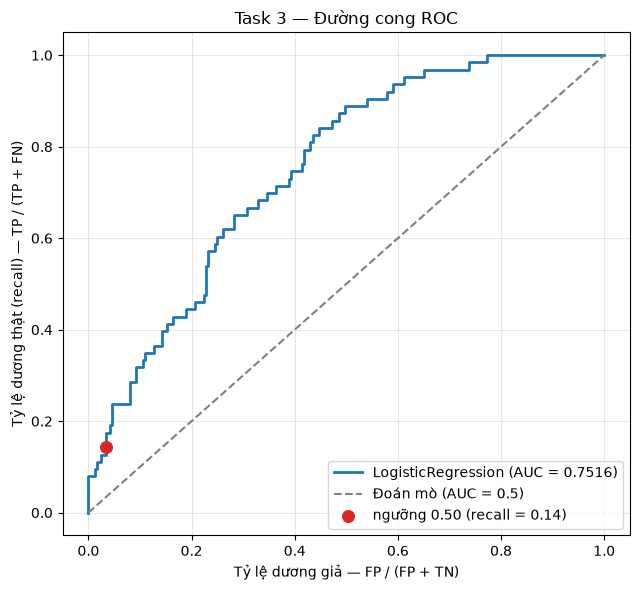

ROC AUC = 0.7516
AUC 0.75 nghĩa là: lấy ngẫu nhiên một khách rời bỏ và một khách ở lại,
mô hình cho người rời bỏ xác suất cao hơn trong khoảng 75 % số lần.


In [21]:
# 3.4 — Đường cong ROC: mô hình có thông tin hay không?
# ROC vẽ tỷ lệ dương thật (recall) theo tỷ lệ dương giả, khi ngưỡng quét từ 1 về 0.
# Nó KHÔNG phụ thuộc vào ngưỡng — nên nó trả lời câu hỏi "mô hình có biết gì không?"
# tách rời khỏi câu hỏi "ta nên cắt ở đâu?".

# TODO: roc_curve(y_thật, xác_suất) trả về (fpr, tpr, các ngưỡng)
fpr, tpr, nguong_roc = roc_curve(y_kh_test, xac_suat)
# TODO: diện tích dưới đường cong
auc = roc_auc_score(y_kh_test, xac_suat)

plt.figure(figsize=(6.5, 6))
plt.plot(fpr, tpr, color="#1f77b4", lw=2, label=f"LogisticRegression (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], "--", color="grey", label="Đoán mò (AUC = 0.5)")

# Đánh dấu điểm hoạt động ở ngưỡng mặc định 0.5
plt.scatter([fp / (tn + fp)], [tp / (tp + fn)], color="#d62728", zorder=5, s=70,
            label=f"ngưỡng 0.50 (recall = {tp / (tp + fn):.2f})")

plt.xlabel("Tỷ lệ dương giả — FP / (FP + TN)")
plt.ylabel("Tỷ lệ dương thật (recall) — TP / (TP + FN)")
plt.title("Task 3 — Đường cong ROC")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"ROC AUC = {auc:.4f}")
assert auc > 0.7, "AUC phải rõ rệt trên 0.5 — mô hình thật sự có thông tin"
print("AUC 0.75 nghĩa là: lấy ngẫu nhiên một khách rời bỏ và một khách ở lại,")
print("mô hình cho người rời bỏ xác suất cao hơn trong khoảng 75 % số lần.")

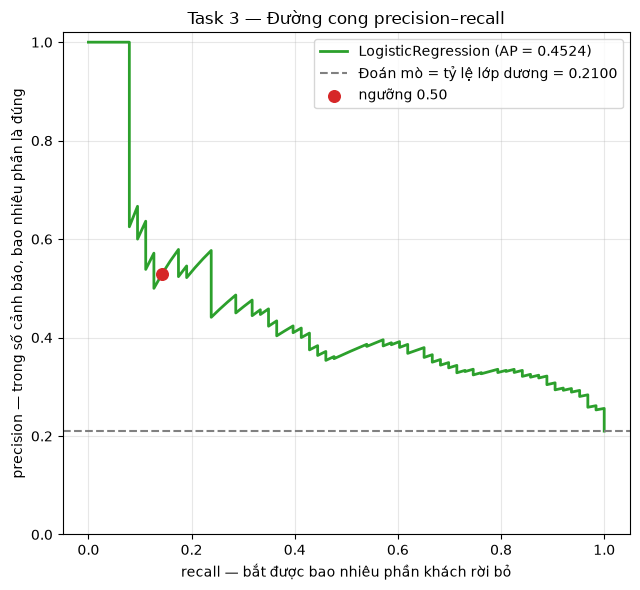

Average precision = 0.4524 (đường nền = 0.2100)

Đường cong đi xuống từ trái sang phải: muốn recall cao hơn thì phải chấp nhận
precision thấp hơn. KHÔNG có ngưỡng nào tốt cho cả hai — đó là một sự đánh đổi,
và chọn điểm nào trên đường cong này là việc của NGHIỆP VỤ, không phải của mô hình.


In [22]:
# 3.5 — Đường cong precision–recall: trung thực hơn ROC khi dữ liệu mất cân bằng
# ROC dùng tỷ lệ dương giả, mà mẫu số của nó (237 khách ở lại) rất lớn, nên ROC trông "đẹp"
# ngay cả khi mô hình gắn cờ sai rất nhiều. Precision–recall nhìn thẳng vào chất lượng cảnh báo.

# TODO: precision_recall_curve(y_thật, xác_suất) -> (precision, recall, các ngưỡng)
prec, rec, nguong_pr = precision_recall_curve(y_kh_test, xac_suat)
# TODO: average_precision_score
ap = average_precision_score(y_kh_test, xac_suat)

plt.figure(figsize=(6.5, 6))
plt.plot(rec, prec, color="#2ca02c", lw=2, label=f"LogisticRegression (AP = {ap:.4f})")
plt.axhline(y_kh_test.mean(), ls="--", color="grey",
            label=f"Đoán mò = tỷ lệ lớp dương = {y_kh_test.mean():.4f}")
plt.scatter([tp / (tp + fn)], [tp / (tp + fp)], color="#d62728", zorder=5, s=70,
            label="ngưỡng 0.50")

plt.xlabel("recall — bắt được bao nhiêu phần khách rời bỏ")
plt.ylabel("precision — trong số cảnh báo, bao nhiêu phần là đúng")
plt.title("Task 3 — Đường cong precision–recall")
plt.ylim(0, 1.02)
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Average precision = {ap:.4f} (đường nền = {y_kh_test.mean():.4f})")
print()
print("Đường cong đi xuống từ trái sang phải: muốn recall cao hơn thì phải chấp nhận")
print("precision thấp hơn. KHÔNG có ngưỡng nào tốt cho cả hai — đó là một sự đánh đổi,")
print("và chọn điểm nào trên đường cong này là việc của NGHIỆP VỤ, không phải của mô hình.")

In [23]:
# 3.6 — Quét ngưỡng. KHÔNG huấn luyện lại một lần nào: xac_suat đã có sẵn từ ô 3.2.
dong_nguong = []
for t in np.round(np.arange(0.05, 0.65, 0.05), 2):
    # TODO: dự đoán nhãn bằng cách so xác suất với ngưỡng t (ép về int)
    y_t = (xac_suat >= t).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_kh_test, y_t).ravel()
    dong_nguong.append({
        "nguong": t,
        "so_canh_bao": int(y_t.sum()),
        # TODO: bốn độ đo, nhớ zero_division=0
        "accuracy": accuracy_score(y_kh_test, y_t),
        "precision": precision_score(y_kh_test, y_t, zero_division=0),
        "recall": recall_score(y_kh_test, y_t, zero_division=0),
        "f1": f1_score(y_kh_test, y_t, zero_division=0),
        "bat_duoc": tp_t,
        "bao_nham": fp_t,
        "bo_sot": fn_t,
    })

bang_nguong = pd.DataFrame(dong_nguong)
print(bang_nguong.round(4).to_string(index=False))
print()
print("Đọc cột accuracy từ dưới lên: nó CAO NHẤT ở ngưỡng cao nhất, nơi mô hình gần như")
print("không cảnh báo ai. Tối ưu accuracy ở bài này chính là tối ưu việc không làm gì cả.")

assert bang_nguong["recall"].is_monotonic_decreasing, \
    "Ngưỡng tăng thì recall phải giảm đơn điệu — kiểm tra lại phép so sánh"
assert bang_nguong.loc[0, "recall"] == 1.0, "Ở ngưỡng 0.05 mô hình phải bắt được toàn bộ 63 khách"

 nguong  so_canh_bao  accuracy  precision  recall     f1  bat_duoc  bao_nham  bo_sot
   0.05          268    0.3167     0.2351  1.0000 0.3807        63       205       0
   0.10          210    0.4900     0.2857  0.9524 0.4396        60       150       3
   0.15          166    0.5967     0.3253  0.8571 0.4716        54       112       9
   0.20          135    0.6400     0.3333  0.7143 0.4545        45        90      18
   0.25          102    0.7100     0.3824  0.6190 0.4727        39        63      24
   0.30           80    0.7167     0.3625  0.4603 0.4056        29        51      34
   0.35           63    0.7533     0.4127  0.4127 0.4127        26        37      37
   0.40           39    0.7800     0.4615  0.2857 0.3529        18        21      45
   0.45           25    0.8000     0.5600  0.2222 0.3182        14        11      49
   0.50           17    0.7933     0.5294  0.1429 0.2250         9         8      54
   0.55           14    0.7967     0.5714  0.1270 0.2078         

In [24]:
# 3.7 — MỤC TIÊU NGHIỆP VỤ: "chiến dịch giữ chân phải chạm tới ít nhất 60 % số khách sắp rời bỏ."
# Đây là một yêu cầu của phòng kinh doanh, không phải của mô hình. Việc của ta là dịch nó ra ngưỡng.

MUC_TIEU_RECALL = 0.60

# TODO: ngưỡng LỚN NHẤT trong bảng còn đạt recall >= MUC_TIEU_RECALL
#   (lớn nhất, vì ngưỡng càng cao thì precision càng tốt — ta muốn vừa đủ đạt mục tiêu)
NGUONG_CHON = bang_nguong[bang_nguong["recall"] >= MUC_TIEU_RECALL]["nguong"].max()
dong_chon = bang_nguong[bang_nguong["nguong"] == NGUONG_CHON].iloc[0]
dong_mac_dinh = bang_nguong[bang_nguong["nguong"] == 0.50].iloc[0]

print(f"Ngưỡng đáp ứng được mục tiêu recall >= {MUC_TIEU_RECALL:.0%}: {NGUONG_CHON}")
print()
print(f"{'':16s} {'ngưỡng 0.50':>14s} {'ngưỡng ' + str(NGUONG_CHON):>14s}")
print("-" * 48)
for k in ["recall", "precision", "f1", "accuracy"]:
    print(f"{k:16s} {dong_mac_dinh[k]:14.4f} {dong_chon[k]:14.4f}")
for k in ["so_canh_bao", "bat_duoc", "bao_nham", "bo_sot"]:
    print(f"{k:16s} {int(dong_mac_dinh[k]):14d} {int(dong_chon[k]):14d}")

print()
print(f"CÁI ĐƯỢC : bắt thêm {int(dong_chon['bat_duoc'] - dong_mac_dinh['bat_duoc'])} khách sắp rời bỏ "
      f"({int(dong_mac_dinh['bat_duoc'])} -> {int(dong_chon['bat_duoc'])} trên 63).")
print(f"CÁI MẤT   : precision tụt {dong_mac_dinh['precision']:.4f} -> {dong_chon['precision']:.4f} "
      f"({dong_chon['precision'] - dong_mac_dinh['precision']:+.4f}).")
print(f"            Số voucher phải phát tăng từ {int(dong_mac_dinh['so_canh_bao'])} lên "
      f"{int(dong_chon['so_canh_bao'])}, trong đó {int(dong_chon['bao_nham'])} là phát nhầm.")
print(f"            accuracy tụt xuống {dong_chon['accuracy']:.4f}, THẤP HƠN baseline {baseline_test:.4f}.")
print()
print("Ô này KHÔNG gọi fit() lần nào. Mô hình không hề đổi — chỉ có quyết định đổi.")

assert dong_chon["recall"] >= MUC_TIEU_RECALL
assert dong_chon["precision"] < dong_mac_dinh["precision"], "Tăng recall thì phải trả giá bằng precision"

Ngưỡng đáp ứng được mục tiêu recall >= 60%: 0.25

                    ngưỡng 0.50    ngưỡng 0.25
------------------------------------------------
recall                   0.1429         0.6190
precision                0.5294         0.3824
f1                       0.2250         0.4727
accuracy                 0.7933         0.7100
so_canh_bao                  17            102
bat_duoc                      9             39
bao_nham                      8             63
bo_sot                       54             24

CÁI ĐƯỢC : bắt thêm 30 khách sắp rời bỏ (9 -> 39 trên 63).
CÁI MẤT   : precision tụt 0.5294 -> 0.3824 (-0.1471).
            Số voucher phải phát tăng từ 17 lên 102, trong đó 63 là phát nhầm.
            accuracy tụt xuống 0.7100, THẤP HƠN baseline 0.7900.

Ô này KHÔNG gọi fit() lần nào. Mô hình không hề đổi — chỉ có quyết định đổi.


**3.8 — Trả lời bằng chữ (bắt buộc).** 3–5 câu.

1. **Vì sao 0,5 không phải là một ngưỡng "đúng"?** Nó đến từ đâu, và vì sao nó thường sai trên dữ
   liệu mất cân bằng?
2. Ở ngưỡng bạn chọn, **accuracy tụt xuống 0,7100 — thấp hơn cả baseline 0,7900.** Hãy bảo vệ lựa
   chọn đó trước một trưởng phòng chỉ nhìn accuracy. Dùng số bỏ sót và số báo động nhầm ở ô 3.7,
   quy ra tiền theo chi phí của Tuần 3: bỏ sót 1 200 000 đ, báo động nhầm 50 000 đ.
3. Ô 3.6 và 3.7 **không gọi `fit()` một lần nào**. Điều đó nói lên gì về quan hệ giữa **huấn luyện
   mô hình** và **ra quyết định**? Nêu một hệ quả thực tế trong vận hành (gợi ý: điều gì xảy ra khi
   ngân sách chiến dịch bị cắt một nửa vào tuần sau?).

*Trả lời:
1. Ngưỡng 0,5 không phải là một ngưỡng "đúng" vì nó chỉ là mặc định toán học của thư viện (xác suất > 50%). Trên dữ liệu mất cân bằng, ngưỡng này thường bỏ sót rất nhiều khách hàng rời bỏ (recall thấp) vì mô hình thận trọng khi gán nhãn dương.
2. Dù accuracy giảm xuống 0.7100 (thấp hơn baseline 0.7900), lựa chọn này vẫn ưu việt hơn từ góc độ kinh doanh. Bằng cách hạ ngưỡng xuống 0.25, ta bắt được 39/63 khách rời bỏ (giảm số khách bỏ sót), giúp giữ chân doanh thu lớn hơn nhiều so với chi phí phát voucher nhầm.
3. Ô 3.6 và 3.7 không gọi lại fit() vì việc huấn luyện mô hình (học xác suất) và việc ra quyết định (chọn ngưỡng cắt) là hai giai đoạn hoàn toàn độc lập. Hệ quả thực tế là khi ngân sách thay đổi, doanh nghiệp chỉ cần điều chỉnh ngưỡng cắt (threshold) mà không tốn chi phí huấn luyện lại mô hình.

---
# Task 4 — Đọc hệ số một cách trung thực (~25 phút)

**Mục tiêu.** Biến bốn hệ số của mô hình ở Task 3 thành một câu tiếng Việt đúng — và biết chính xác
câu đó **không** được phép nói gì.

**Tỉ số odds (odds ratio).** Hồi quy logistic tuyến tính theo **log-odds**, không theo xác suất:

```
log( p / (1 − p) ) = w₁x₁ + w₂x₂ + … + b
```

Nên `exp(wⱼ)` chính là **tỉ số odds**: tăng `xⱼ` thêm một đơn vị thì odds rời bỏ **nhân lên**
`exp(wⱼ)` lần, mọi biến khác giữ nguyên. Lớn hơn 1 = tăng rủi ro, nhỏ hơn 1 = giảm rủi ro, bằng 1 =
không ảnh hưởng.

**Các bước con**

1. **4.1** — Trích hệ số của mô hình **đã chuẩn hóa**, đổi sang tỉ số odds, xếp hạng.
2. **4.2** — Khớp lại mô hình trên dữ liệu **chưa chuẩn hóa** và so hai bảng. Thứ hạng sẽ **đảo lộn**.
3. **4.3** — `permutation_importance` làm phép đối chứng độc lập.
4. **4.4** — Trả lời bằng chữ về **quan hệ nhân quả**.

### Kết quả mong đợi

**(a) Hệ số trên thang chuẩn hóa** — mỗi hệ số là *"một độ lệch chuẩn của biến này"*:

| Đặc trưng | Hệ số | Tỉ số odds | Đọc là |
|---|---|---|---|
| `tong_chi_tieu` | **−0.9379** | **0.3914** | chi tiêu nhiều hơn 1 σ → odds rời bỏ còn **39 %** |
| `thang_gan_nhat` | **+0.5298** | **1.6986** | lâu không mua thêm 1 σ → odds rời bỏ **× 1,70** |
| `so_ticket_ho_tro` | **+0.4640** | **1.5904** | thêm 1 σ phiếu hỗ trợ → odds rời bỏ **× 1,59** |
| `so_don` | −0.1257 | 0.8819 | ảnh hưởng yếu nhất |

**(b) Cùng mô hình, dữ liệu KHÔNG chuẩn hóa** — thứ hạng theo `|hệ số|` **đảo lộn hoàn toàn**:

| Đặc trưng | Hệ số thô | Tỉ số odds thô | Hạng theo `\|hệ số\|` thô | Hạng đã chuẩn hóa |
|---|---|---|---|---|
| `so_ticket_ho_tro` | +0.3131 | 1.3676 | **1** | 3 |
| `so_don` | −0.1419 | 0.8677 | 2 | **4** |
| `thang_gan_nhat` | +0.0525 | 1.0539 | 3 | 2 |
| `tong_chi_tieu` | −0.000000249 | **1.000000** | **4** | **1** |

Đặc trưng **mạnh nhất** theo bảng chuẩn hóa là đặc trưng **yếu nhất** theo bảng thô. Mô hình thô
cũng kém hơn: accuracy **0.7867** so với 0.7933, và cần **116** vòng lặp thay vì **6**.

**(c) `permutation_importance` (scoring = `roc_auc`, 30 lần lặp)** xác nhận thứ hạng của bảng chuẩn hóa:

| Đặc trưng | Mức sụt AUC | Độ lệch chuẩn |
|---|---|---|
| `tong_chi_tieu` | **0.1265** | 0.0243 |
| `thang_gan_nhat` | 0.0909 | 0.0233 |
| `so_ticket_ho_tro` | 0.0345 | 0.0171 |
| `so_don` | 0.0104 | 0.0044 |

In [25]:
# 4.1 — Hệ số -> tỉ số odds, trên mô hình ĐÃ chuẩn hóa của Task 3
# Lấy bước "model" ra khỏi Pipeline. coef_ có dạng (1, n_dac_trung) cho bài nhị phân.
lg = mo_hinh_lg.named_steps["model"]

bang_he_so_lg = pd.DataFrame({
    "dac_trung": DAC_TRUNG_KH,
    "he_so": lg.coef_[0],
})
# TODO: tỉ số odds = e mũ hệ số
bang_he_so_lg["odds_ratio"] = np.exp(bang_he_so_lg["he_so"])
# TODO: sắp xếp theo TRỊ TUYỆT ĐỐI của hệ số, giảm dần (gợi ý: key=abs)
bang_he_so_lg = bang_he_so_lg.reindex(
    bang_he_so_lg["he_so"].abs().sort_values(ascending=False).index
).reset_index(drop=True)
bang_he_so_lg = bang_he_so_lg.reset_index(drop=True)

print(bang_he_so_lg.round(4).to_string(index=False))
print()
print(f"Hệ số chặn (intercept) = {lg.intercept_[0]:.4f}")
print()
print("Đọc thành câu — nhớ rằng 'một đơn vị' ở đây là MỘT ĐỘ LỆCH CHUẨN:")
for _, r in bang_he_so_lg.iterrows():
    if r["odds_ratio"] > 1:
        print(f"  {r['dac_trung']:18s} tăng 1 σ -> odds rời bỏ NHÂN {r['odds_ratio']:.4f}")
    else:
        print(f"  {r['dac_trung']:18s} tăng 1 σ -> odds rời bỏ còn {r['odds_ratio'] * 100:.1f} %")

assert bang_he_so_lg.loc[0, "dac_trung"] == "tong_chi_tieu", \
    "Với seed 42, hệ số mạnh nhất theo trị tuyệt đối là tong_chi_tieu"
assert np.allclose(bang_he_so_lg["odds_ratio"], np.exp(bang_he_so_lg["he_so"]))

       dac_trung   he_so  odds_ratio
   tong_chi_tieu -0.9379      0.3914
  thang_gan_nhat  0.5298      1.6986
so_ticket_ho_tro  0.4640      1.5904
          so_don -0.1257      0.8819

Hệ số chặn (intercept) = -1.6739

Đọc thành câu — nhớ rằng 'một đơn vị' ở đây là MỘT ĐỘ LỆCH CHUẨN:
  tong_chi_tieu      tăng 1 σ -> odds rời bỏ còn 39.1 %
  thang_gan_nhat     tăng 1 σ -> odds rời bỏ NHÂN 1.6986
  so_ticket_ho_tro   tăng 1 σ -> odds rời bỏ NHÂN 1.5904
  so_don             tăng 1 σ -> odds rời bỏ còn 88.2 %


In [26]:
# 4.2 — Cũng mô hình đó, nhưng KHÔNG chuẩn hóa. Xem thứ hạng lật ngược.
# TODO: LogisticRegression khớp thẳng trên X_kh_train (không Pipeline, không scaler)
#   max_iter=5000 vì không chuẩn hóa thì tối ưu rất chậm
mo_hinh_tho = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
mo_hinh_tho.fit(X_kh_train, y_kh_train)

bang_tho = pd.DataFrame({
    "dac_trung": DAC_TRUNG_KH,
    "he_so_tho": mo_hinh_tho.coef_[0],
    "odds_ratio_tho": np.exp(mo_hinh_tho.coef_[0]),
})
print("Bảng hệ số của mô hình CHƯA chuẩn hóa:")
print(bang_tho.round(10).to_string(index=False))
print()

# Ghép hai bảng để so thứ hạng
bang_so_sanh = (bang_he_so_lg.merge(bang_tho, on="dac_trung")
                .assign(hang_chuan_hoa=lambda d: d["he_so"].abs().rank(ascending=False).astype(int),
                        hang_tho=lambda d: d["he_so_tho"].abs().rank(ascending=False).astype(int)))
print(bang_so_sanh[["dac_trung", "he_so", "hang_chuan_hoa", "he_so_tho", "hang_tho"]]
      .to_string(index=False))
print()
print(f"accuracy mô hình thô = {mo_hinh_tho.score(X_kh_test, y_kh_test):.4f}  "
      f"(mô hình chuẩn hóa: {acc:.4f})")
print(f"số vòng lặp mô hình thô = {mo_hinh_tho.n_iter_[0]}  "
      f"(mô hình chuẩn hóa: {mo_hinh_lg.named_steps['model'].n_iter_[0]})")
print()
print("VÌ SAO bảng thô vô dụng: đơn vị của mỗi hệ số là 'trên MỘT ĐƠN VỊ GỐC của cột đó'.")
print(f"  tong_chi_tieu: odds ratio = {np.exp(mo_hinh_tho.coef_[0][1]):.8f} cho MỖI 1 ĐỒNG.")
print(f"  Quy về mỗi 1 TRIỆU đồng: {np.exp(mo_hinh_tho.coef_[0][1] * 1_000_000):.4f} — mới đọc được.")
print("  So hệ số 'trên 1 đồng' với hệ số 'trên 1 phiếu hỗ trợ' là so mét với ki-lô-gam.")

assert bang_so_sanh.loc[bang_so_sanh["dac_trung"] == "tong_chi_tieu", "hang_chuan_hoa"].iloc[0] == 1
assert bang_so_sanh.loc[bang_so_sanh["dac_trung"] == "tong_chi_tieu", "hang_tho"].iloc[0] == 4

Bảng hệ số của mô hình CHƯA chuẩn hóa:
       dac_trung     he_so_tho  odds_ratio_tho
  thang_gan_nhat  5.245182e-02        1.053852
   tong_chi_tieu -2.489000e-07        1.000000
          so_don -1.418618e-01        0.867741
so_ticket_ho_tro  3.130821e-01        1.367634

       dac_trung     he_so  hang_chuan_hoa     he_so_tho  hang_tho
   tong_chi_tieu -0.937928               1 -2.488731e-07         4
  thang_gan_nhat  0.529793               2  5.245182e-02         3
so_ticket_ho_tro  0.463983               3  3.130821e-01         1
          so_don -0.125678               4 -1.418618e-01         2

accuracy mô hình thô = 0.7867  (mô hình chuẩn hóa: 0.7933)
số vòng lặp mô hình thô = 105  (mô hình chuẩn hóa: 6)

VÌ SAO bảng thô vô dụng: đơn vị của mỗi hệ số là 'trên MỘT ĐƠN VỊ GỐC của cột đó'.
  tong_chi_tieu: odds ratio = 0.99999975 cho MỖI 1 ĐỒNG.
  Quy về mỗi 1 TRIỆU đồng: 0.7797 — mới đọc được.
  So hệ số 'trên 1 đồng' với hệ số 'trên 1 phiếu hỗ trợ' là so mét với ki-lô-gam.


In [27]:
# 4.3 — Đối chứng độc lập: permutation_importance
# Ý tưởng: xáo trộn ngẫu nhiên MỘT cột rồi đo mô hình tệ đi bao nhiêu. Cột nào quan trọng thì
# xáo nó vào sẽ làm điểm số sụt mạnh. Cách này KHÔNG dựa vào hệ số, nên nó là một phép kiểm chứng
# thật sự — và nó dùng được cho cả mô hình phi tuyến (rừng ngẫu nhiên, mạng nơ-ron).
#
# Chọn scoring="roc_auc" chứ KHÔNG dùng accuracy: ở ngưỡng 0.5 mô hình gần như không dự đoán lớp 1,
# nên accuracy gần như không nhúc nhích dù xáo cột nào — đúng bài học của Task 3.

# TODO: permutation_importance(mô_hình, X kiểm tra, y kiểm tra,
#         n_repeats=30, random_state=RANDOM_STATE, scoring="roc_auc")
pi = permutation_importance(
    mo_hinh_lg, X_kh_test, y_kh_test, 
    n_repeats=30, random_state=RANDOM_STATE, scoring="roc_auc"
)

bang_pi = pd.DataFrame({
    "dac_trung": DAC_TRUNG_KH,
    "muc_sut_auc": pi.importances_mean,
    "do_lech_chuan": pi.importances_std,
}).sort_values("muc_sut_auc", ascending=False).reset_index(drop=True)

print(bang_pi.round(4).to_string(index=False))
print()
print("Thứ hạng theo hệ số (đã chuẩn hóa):", list(bang_he_so_lg["dac_trung"]))
print("Thứ hạng theo permutation      :", list(bang_pi["dac_trung"]))

assert list(bang_pi["dac_trung"]) == list(bang_he_so_lg["dac_trung"]), \
    "Hai cách xếp hạng phải trùng nhau — với mô hình tuyến tính đã chuẩn hóa thì đó là điều mong đợi"
print()
print("Hai phương pháp độc lập cho cùng một thứ hạng -> kết quả đáng tin.")
print("Lưu ý: nếu hai bảng KHÁC nhau thì đó là dấu hiệu có tương quan giữa các đặc trưng")
print("(như cặp song sinh ở Task 2), và khi đó KHÔNG được đọc hệ số như là tầm quan trọng.")

       dac_trung  muc_sut_auc  do_lech_chuan
   tong_chi_tieu       0.1265         0.0243
  thang_gan_nhat       0.0909         0.0233
so_ticket_ho_tro       0.0345         0.0171
          so_don       0.0104         0.0044

Thứ hạng theo hệ số (đã chuẩn hóa): ['tong_chi_tieu', 'thang_gan_nhat', 'so_ticket_ho_tro', 'so_don']
Thứ hạng theo permutation      : ['tong_chi_tieu', 'thang_gan_nhat', 'so_ticket_ho_tro', 'so_don']

Hai phương pháp độc lập cho cùng một thứ hạng -> kết quả đáng tin.
Lưu ý: nếu hai bảng KHÁC nhau thì đó là dấu hiệu có tương quan giữa các đặc trưng
(như cặp song sinh ở Task 2), và khi đó KHÔNG được đọc hệ số như là tầm quan trọng.


**4.4 — Trả lời bằng chữ (bắt buộc).** Đây là phần viết quan trọng nhất của buổi.

Nhìn vào bảng 4.1. Hai hệ số **dương** là `thang_gan_nhat` (+0,5298) và `so_ticket_ho_tro` (+0,4640).
Ta tập trung vào `so_ticket_ho_tro`, tỉ số odds **1,5904**.

1. **Viết câu mô tả đúng về mặt thống kê** cho hệ số này — câu mà bạn dám đưa vào báo cáo.
2. **Viết 2–3 câu giải thích vì sao một hệ số dương KHÔNG chứng minh quan hệ nhân quả.** Nêu **ít
   nhất hai** cách giải thích khác cho cùng mối liên hệ đó, ngoài cách "phiếu hỗ trợ khiến khách rời bỏ".
3. **Một can thiệp sai lầm.** Ban giám đốc đọc bảng này và đề xuất: *"giảm số phiếu hỗ trợ xuống —
   ẩn nút liên hệ đi, bắt khách tự tra cứu trước khi được gửi phiếu."* Chuyện gì sẽ xảy ra với tỷ lệ
   rời bỏ thật sự? Vì sao?
4. **Bạn cần dữ liệu gì** để kết luận được quan hệ nhân quả ở đây? (Một câu là đủ.)

*Trả lời: 
1. Câu mô tả thống kê cho so_ticket_ho_tro (odds ratio ≈ 1.59): Khi số phiếu hỗ trợ tăng thêm một độ lệch chuẩn (giữ nguyên các biến khác), odds khách hàng rời bỏ sẽ nhân lên khoảng 1,59 lần (tăng 59%).
2. Hệ số dương KHÔNG chứng minh quan hệ nhân quả vì mô hình chỉ bắt được tương quan thống kê, không loại trừ được yếu tố nhiễu hay quan hệ đảo chiều. Các cách giải thích khác ngoài việc "phiếu hỗ trợ khiến khách rời bỏ":
   - Do khách đã gặp sẵn sự cố nghiêm trọng từ trước (sản phẩm lỗi, giao hàng chậm) nên họ mới phải tạo nhiều phiếu hỗ trợ. Chính sự cố đó mới là nguyên nhân khiến họ muốn rời bỏ, chứ không phải do chiếc phiếu hỗ trợ gây ra.
   - Khách hàng VIP tương tác nhiều hơn, mua sắm nhiều hơn nên số lượng yêu cầu hỗ trợ phát sinh cũng cao hơn theo tỉ lệ thuận.
3. Can thiệp sai lầm (ẩn nút liên hệ, giảm số phiếu hỗ trợ): Tỷ lệ rời bỏ thực tế sẽ TĂNG LÊN chứ không giảm. Việc che giấu kênh hỗ trợ chỉ làm khách hàng thêm bực bội, bất mãn và từ bỏ dịch vụ nhanh hơn mà doanh nghiệp hoàn toàn không hay biết nguyên nhân gốc rễ.
4. Dữ liệu cần thiết để kết luận quan hệ nhân quả: Dữ liệu từ các thí nghiệm ngẫu nhiên có kiểm soát (A/B testing) hoặc phương pháp suy luận nhân quả (causal inference / instrumental variables).

---
# Mở rộng (không bắt buộc) — Đưa `quan` vào mô hình bằng `ColumnTransformer`

Làm phần này nếu bạn đã xong bốn task và còn thời gian.

Cả buổi hôm nay ta bỏ qua cột `quan`, vì nó là **phân loại** chứ không phải số — mà `Ridge` và
`Lasso` chỉ nhân được với số. Công cụ để xử lý, `ColumnTransformer` + `OneHotEncoder`, bạn đã học ở
Tuần 4: nó áp `StandardScaler` cho nhóm cột số và `OneHotEncoder` cho nhóm cột phân loại, trong cùng
một `Pipeline`.

`drop="first"` bỏ một hạng mục làm **mốc so sánh** — ở đây là `Bình Thạnh` (đứng đầu theo thứ tự
sắp xếp). Mọi hệ số quận còn lại đọc là *"so với Bình Thạnh"*.

**Các bước con**

1. **M.1** — Dựng `ColumnTransformer`, khớp `Ridge`, `Lasso`, OLS. So R² với Task 2.
2. **M.2** — In hệ số của năm quận và đối chiếu với giá trung bình thực tế theo quận.
3. **M.3** — Trả lời bằng chữ.

### Kết quả mong đợi

| Mô hình | R² kiểm tra (không có `quan`) | R² kiểm tra (**có** `quan`) | Thay đổi |
|---|---|---|---|
| OLS | 0.6518 | 0.9222 | **+0.2703** |
| `Ridge(alpha=1)` | 0.6549 | **0.9223** | **+0.2673** |
| `Lasso(alpha=0.05)` | 0.6609 | 0.9148 | +0.2538 |

Số cột sau mã hóa: **16** (11 cột số + 5 cột quận). Hệ số quận của `Ridge` (mốc = `Bình Thạnh`):

| Quận | Hệ số | Giá trung bình thực tế (tỷ) |
|---|---|---|
| `Quận 1` | **+4.2205** | 11.291 |
| `Quận 3` | +2.5501 | 9.644 |
| `Quận 7` | +0.7919 | 7.656 |
| *(Bình Thạnh — mốc)* | *0* | 6.774 |
| `Gò Vấp` | −0.7283 | 5.639 |
| `Thủ Đức` | −1.1942 | 5.618 |

Thứ tự hệ số trùng khít thứ tự giá trung bình — dấu hiệu mô hình đã học đúng thứ nó cần học.

In [28]:
# M.1 — ColumnTransformer: cột số đi một đường, cột phân loại đi một đường khác
X_quan = nha[DAC_TRUNG_SO + ["quan"]]
Xq_train, Xq_test, yq_train, yq_test = train_test_split(
    X_quan, y_ty, test_size=0.2, random_state=RANDOM_STATE)

# TODO: ColumnTransformer với hai nhánh:
#   ("num", StandardScaler(), DAC_TRUNG_SO)
#   ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), ["quan"])
tien_xu_ly = ColumnTransformer([
    ("num", StandardScaler(), DAC_TRUNG_SO),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), ["quan"])
])

print(f"{'Mô hình':<20} {'R² không quan':>14} {'R² có quan':>12} {'thay đổi':>10}")
print("-" * 60)
mo_hinh_quan = {}
for i, (ten, mdl) in enumerate([("OLS", LinearRegression()),
                                ("Ridge(alpha=1)", Ridge(alpha=1.0)),
                                ("Lasso(alpha=0.05)", Lasso(alpha=0.05, random_state=RANDOM_STATE))]):
    # TODO: Pipeline([("pre", tien_xu_ly), ("model", mdl)]) rồi fit trên (Xq_train, yq_train)
    p = Pipeline([
        ("pre", tien_xu_ly),
        ("model", mdl)
    ])
    p.fit(Xq_train, yq_train)
    mo_hinh_quan[ten] = p
    r2_moi = p.score(Xq_test, yq_test)
    r2_cu = bang_r2.loc[i, "R2_test"]
    print(f"{ten:<20} {r2_cu:14.4f} {r2_moi:12.4f} {r2_moi - r2_cu:+10.4f}")

ten_cot = mo_hinh_quan["Ridge(alpha=1)"].named_steps["pre"].get_feature_names_out()
print()
print(f"Số cột sau khi mã hóa: {len(ten_cot)}  (11 cột số + {len(ten_cot) - 11} cột quận)")

assert len(ten_cot) == 16, "6 quận, drop='first' -> 5 cột quận + 11 cột số = 16"
assert mo_hinh_quan["Ridge(alpha=1)"].score(Xq_test, yq_test) > 0.9

Mô hình               R² không quan   R² có quan   thay đổi
------------------------------------------------------------
OLS                          0.6518       0.9222    +0.2703
Ridge(alpha=1)               0.6549       0.9223    +0.2673
Lasso(alpha=0.05)            0.6609       0.9148    +0.2538

Số cột sau khi mã hóa: 16  (11 cột số + 5 cột quận)


In [29]:
# M.2 — Hệ số của từng quận, đối chiếu với giá trung bình thực tế
ridge_quan = mo_hinh_quan["Ridge(alpha=1)"]
w_quan = ridge_quan.named_steps["model"].coef_

bang_quan = pd.DataFrame({"cot": ten_cot, "he_so": w_quan})
bang_quan = bang_quan[bang_quan["cot"].str.startswith("cat__")].copy()
bang_quan["quan"] = bang_quan["cot"].str.replace("cat__quan_", "", regex=False)

# TODO: giá trung bình thực tế theo quận (groupby trên nha)
gia_tb = nha.groupby("quan")["gia_ty_vnd"].mean()
bang_quan["gia_tb_thuc_te"] = bang_quan["quan"].map(gia_tb)
bang_quan = bang_quan.sort_values("he_so", ascending=False)

print("Hệ số quận (mốc so sánh = Bình Thạnh, bị drop='first' loại bỏ):")
print(bang_quan[["quan", "he_so", "gia_tb_thuc_te"]].round(4).to_string(index=False))
print()
print(f"Giá trung bình thực tế của quận mốc Bình Thạnh: {gia_tb['Bình Thạnh']:.3f} tỷ")
print()
print("Hai cột diện tích sau khi thêm quan:")
for j, ten in enumerate(ten_cot[:2]):
    print(f"  {ten:28s} {w_quan[j]:8.4f}")
print()
print("Kiểm chứng: thứ tự hệ số có trùng thứ tự giá trung bình không?")
theo_he_so = list(bang_quan["quan"])
theo_gia = list(bang_quan.sort_values("gia_tb_thuc_te", ascending=False)["quan"])
print(f"  theo hệ số      : {theo_he_so}")
print(f"  theo giá trung bình: {theo_gia}")
assert theo_he_so == theo_gia, "Thứ tự phải trùng nhau"
print("  -> TRÙNG. Mô hình đã học đúng thứ hạng giá theo quận.")

Hệ số quận (mốc so sánh = Bình Thạnh, bị drop='first' loại bỏ):
   quan   he_so  gia_tb_thuc_te
 Quận 1  4.2205         11.2907
 Quận 3  2.5501          9.6440
 Quận 7  0.7919          7.6564
 Gò Vấp -0.7283          5.6385
Thủ Đức -1.1942          5.6184

Giá trung bình thực tế của quận mốc Bình Thạnh: 6.774 tỷ

Hai cột diện tích sau khi thêm quan:
  num__dien_tich_m2              1.1531
  num__dien_tich_sqft            1.1528

Kiểm chứng: thứ tự hệ số có trùng thứ tự giá trung bình không?
  theo hệ số      : ['Quận 1', 'Quận 3', 'Quận 7', 'Gò Vấp', 'Thủ Đức']
  theo giá trung bình: ['Quận 1', 'Quận 3', 'Quận 7', 'Gò Vấp', 'Thủ Đức']
  -> TRÙNG. Mô hình đã học đúng thứ hạng giá theo quận.


**M.3 — Trả lời bằng chữ (không bắt buộc).**

R² tăng từ 0,6549 lên 0,9223 nhờ **một** cột, trong khi cả Task 2 ta chỉnh `alpha` chỉ giành được
chưa tới 0,01. **Điều đó nói gì về thứ tự ưu tiên khi cải thiện một mô hình?** Và vì sao ta vẫn
không được bỏ qua Task 2?

*Trả lời: 
R² tăng vọt từ ~0.65 lên ~0.92 cho thấy việc bổ sung đúng biến phân loại quan trọng (vị trí quận) có ý nghĩa quyết định đến chất lượng dự báo của mô hình — việc chọn đúng đặc trưng chủ chốt mang lại hiệu quả lớn hơn nhiều so với tinh chỉnh tham số alpha. Tuy nhiên, ta vẫn không được bỏ qua Task 2 vì nếu không kiểm soát hiện tượng đa cộng tuyến và loại bỏ cột nhiễu, mô hình sẽ bị bùng nổ hệ số, kém ổn định và không thể dùng bảng hệ số để giải thích chính xác ý nghĩa kinh tế cho doanh nghiệp.

---
# Danh mục kiểm tra trước khi nộp

Chạy **Kernel → Restart & Run All** lần cuối, rồi soát từng dòng:

**Mã chạy được**
- [ ] Notebook chạy từ đầu đến cuối, không có ô nào báo lỗi.
- [ ] Không còn dòng `...` hay chữ `TODO` nào trong các ô mã.
- [ ] Mọi `assert` trong notebook đều chạy qua.
- [ ] Mọi chỗ ngẫu nhiên đều dùng `random_state=RANDOM_STATE` (= 42).

**Kết quả đúng**
- [ ] Task 1: `w = 2.807884`, `b = 7.505015`, sai lệch so với `LinearRegression` cỡ `1e-15`.
- [ ] Task 1: `lr = 1.5` làm mất mát bùng nổ lên cỡ `1e+19`.
- [ ] Task 2: bảng hệ số cho `dien_tich_m2` **−431.9020** (OLS) và `+1.1300` (Ridge).
- [ ] Task 2: `Lasso` ép đúng **2** cột nhiễu về 0; `LassoCV` chọn `alpha = 0.0413`.
- [ ] Task 3: accuracy **0.7933** ở ngưỡng 0,5; **ROC AUC = 0.7516**; ngưỡng chọn = **0.25**.
- [ ] Task 4: `tong_chi_tieu` đứng **nhất** ở bảng chuẩn hóa và **bét** ở bảng thô.

**Đồ thị** (chấm cả tính đầy đủ của nhãn)
- [ ] Đường cong mất mát Task 1 — hai khung, có nhãn trục, có chú giải.
- [ ] Đường đi hệ số Task 2 — hai khung, trục hoành thang log, có chú giải tên đặc trưng.
- [ ] ROC Task 3 — có đường chéo đoán mò và điểm hoạt động ngưỡng 0,5.
- [ ] Precision–recall Task 3 — có đường nền bằng tỷ lệ lớp dương.

**Phần viết** (chấm ngang phần mã)
- [ ] Task 1 mục 1.6 — vì sao cần chuẩn hóa, và chuyện gì xảy ra khi `lr` quá lớn.
- [ ] Task 2 mục 2.5 — **R² như nhau thì chọn mô hình nào có gì quan trọng** (ít nhất hai hậu quả).
- [ ] Task 2 mục 2.10 — bảng tổng kết đã điền + một câu khuyến nghị.
- [ ] Task 3 mục 3.8 — ngưỡng 0,5 không thiêng, và bảo vệ được lựa chọn accuracy thấp hơn baseline.
- [ ] Task 4 mục 4.4 — **vì sao hệ số dương không chứng minh nhân quả** + hai cách giải thích khác.

**Nộp bài**
- [ ] Đổi tên tệp thành `Tuan05_ThucHanh_<MSSV>.ipynb`.
- [ ] Giữ nguyên toàn bộ kết quả in ra và đồ thị (đừng xóa output trước khi nộp).
- [ ] Nộp trước khi rời phòng máy.

---

### Tuần sau

Tuần 6 rời khỏi mô hình tuyến tính: cây quyết định, rừng ngẫu nhiên và SVM trên đúng hai bộ dữ liệu
này. Câu hỏi mở đầu sẽ là: *cây quyết định có bị đa cộng tuyến làm hỏng như OLS không?* Mang theo
notebook này — bảng hệ số của Task 2 sẽ được đem ra so sánh ngay từ ô đầu tiên.